# 1. Library imports

In [1]:
import os
from IPython.display import display
from functools import partial

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import kstest, skew, kurtosis

from volatility_pipeline.models import tuned_factory
from volatility_pipeline.data import prepare_series, load_ohlc, describe_source
from volatility_pipeline.models import (
    RealizedGARCH, make_realized_garch,
    GARCHModel, make_garch, XGBVolatilityModel, XGBHybridModel,
    LSTMVolatilityModel, LSTMHybridModel,
    param_matrix,
    pvalue_matrix, asymmetry_summary, persistence, equations_markdown, scale_note,
)
from volatility_pipeline.evaluation import (
    RollingEvaluator,
    ForecastResult,
    dm_matrix,
    dm_family_split,
    dm_vs_benchmark,
    rescore,
    exclude_dates,
    hyperparameter_table,
    equal_weight_combination,
    export_run,
    collect_config,
    run_directory,
    mcs,
    arch_mcs,
    garman_klass,
    parkinson,
    squared_returns,
    compute_proxy,
    overnight_gap_report,
    yang_zhang,
    forecast_diagnostics,
    normality_report,
    bai_ng_normality,
    residual_report,
    residual_diagnostics_table,
)


# 2. Configuration

In [2]:
# ════════════════════════════════════════════════════════════════════════════
# DEFAULTS = THE ARTICLE'S FROZEN SPECIFICATION (supervisor, October 2026).
# Every option the specification switches off is kept below as a commented-out
# line, or listed in the comment next to its setting, so it can be switched
# back on. Run once per commodity: TICKER = "BZ=F" and TICKER = "NG=F".
# ════════════════════════════════════════════════════════════════════════════

# ── Input data ───────────────────────────────────────────────────────────────
TICKER          = "BZ=F"   # "BZ=F" (Brent) | "NG=F" (Henry Hub): the article runs both
FULL_DATA_START = "2010-01-01"
FULL_DATA_END   = "2026-06-30"   # exclusive (yfinance): last day 2026-06-29

TRAIN_START = FULL_DATA_START
TRAIN_END   = "2022-06-30"
TEST_START  = "2022-07-01"
TEST_END    = FULL_DATA_END

# ── Data snapshot and results export ──────────────────────────────────────────
# DATA_SNAPSHOT pins the Yahoo download, so a later revision of Yahoo's data
# cannot move the results:
#   "auto"    -> read the snapshot if it exists, otherwise download and save it
#   "refresh" -> download again and overwrite the snapshot
#   "off"     -> always download, never read or write a snapshot
# One CSV per ticker and date range in DATA_SNAPSHOT_DIR, with a SHA-256 checked
# on every load. Relative paths are taken from the REPOSITORY ROOT, so a copy of
# this notebook in experiments/<date>/ reads the same snapshot.
DATA_SNAPSHOT     = "auto"   # 'auto' | 'refresh' | 'off'
DATA_SNAPSHOT_DIR = None     # None -> <repo>/data

# EXPORT_RESULTS writes, at the end of the notebook, everything needed to rebuild
# the tables without re-running: every model's forecasts and per-day losses, the
# metrics, DM and MCS tables, diagnostics, coefficients and hyperparameters, plus
# a run_config.json with every setting in this cell, the data snapshot's hash,
# the git commit and package versions.
#
# Every run gets its own folder, named by when it ran and what it is:
#   <EXPORT_ROOT>/<TICKER>/<YYYY-MM-DD_HHMM>_<RUN_LABEL>   e.g. results/NG=F/2026-10-20_1432_main
# so no run overwrites another. The time is taken when THIS cell runs: re-running
# the whole notebook makes a new folder, re-running only the export cell rewrites
# the same one. EXPORT_ROOT is taken from the repository root. results/ is
# git-ignored and meant for scratch runs; for runs that are kept, point it into
# the experiment folder, e.g.
#   EXPORT_ROOT = "experiments/20.10.2026/results"
# RUN_LABEL says what the run is: "main", "roll-drop", "sliding750", "debug", ...
EXPORT_RESULTS = True    # False -> nothing is written
EXPORT_ROOT    = "experiments/17.10.2026/results"
RUN_LABEL      = "sliding750"   # this notebook's defaults are the specification
EXPORT_DIR     = run_directory(EXPORT_ROOT, TICKER, RUN_LABEL)
REPORT_METRICS = ["QLIKE", "RMSE"]   # specification; add "MAE", "MSE" to export them too

# ── Classical econometric model specifications ────────────────────────────────
# Each tuple: (model_type, error_distribution)
# model_type:  'GARCH' | 'GJR-GARCH' | 'EGARCH' | 'APARCH' | 'FIGARCH'
# dist:        'normal' | 't' | 'ged'
# The specification estimates every family with Normal and Student-t errors.
# GED was dropped: in the PIT it behaves like t (both retained 5/5 on both
# commodities) and adds nothing to the Normal-vs-t contrast. To restore it,
# uncomment the "ged" lines.
GARCH_SPECS = [
    ("GARCH",     "normal"),
    ("GARCH",     "t"),
    # ("GARCH",     "ged"),
    ("GJR-GARCH", "normal"),
    ("GJR-GARCH", "t"),
    # ("GJR-GARCH", "ged"),
    ("EGARCH",    "normal"),
    ("EGARCH",    "t"),
    # ("EGARCH",    "ged"),
    ("APARCH",    "normal"),
    ("APARCH",    "t"),
    # ("APARCH",    "ged"),
    ("FIGARCH",   "normal"),
    ("FIGARCH",   "t"),
    # ("FIGARCH",   "ged"),
]

# ASYM_ORDER sets the asymmetric (leverage) order `o` of the EGARCH and APARCH
# specifications, which are asymmetric by construction in the literature
# (Nelson 1991; Ding et al. 1993):
#   1 -> asymmetric: a leverage coefficient gamma is estimated (default)
#   0 -> symmetric variants instead (log-variance GARCH / plain Power ARCH)
# It is applied ONLY to EGARCH and APARCH. GARCH and GJR-GARCH are *defined* by
# o=0 and o=1 respectively (changing o would turn one into the other), and
# arch's FIGARCH has no asymmetric term — make_garch ignores the setting there.
# NOTE: arch_model()'s own default is o=0, so omitting it silently estimates the
# symmetric variant; that is why this is passed explicitly.
ASYM_ORDER = 1  # 1 | 0  — EGARCH / APARCH only

# ── Out-of-sample evaluation (shared by all models) ───────────────────────────
N_AHEAD     = 1   # forecast horizon; only 1 is currently supported
REFIT_EVERY = 10  # re-estimate parameters every N test steps

# WINDOW_TYPE controls the estimation scheme used during out-of-sample evaluation:
#   "expanding" — recursive: each step uses all data from the start up to t
#   "sliding"   — rolling: each step uses a fixed window of WINDOW_SIZE obs
# The specification uses "expanding"; the robustness check is a sliding
# window of 750 days: WINDOW_TYPE = "sliding", WINDOW_SIZE = 750.
WINDOW_TYPE = "sliding"  # 'expanding' | 'sliding'

# WINDOW_SIZE sets the sliding-window width in observations (ignored when
# WINDOW_TYPE="expanding"). None -> full training length (~3110 obs, ~12y),
# which overlaps almost entirely with the expanding window over a ~4y test and
# therefore shows negligible differences. Use a NARROW width to probe
# sensitivity to the 2020/2022 regime shifts, e.g. 750 (~3y) or 500 (~2y).
# NOTE: applies to every model group (GARCH, XGB, hybrid, LSTM) since they
# share the same evaluator settings; a narrow window also shortens each ML
# training set.
WINDOW_SIZE = 750  # None | 750 | 500 | int (must be <= training length)

# VARIANCE_PROXY controls the realized-variance proxy used as the forecast target.
#
# WHICH QUANTITY each proxy measures matters more here than how noisy it is. A
# GARCH model estimated on close-to-close returns forecasts the FULL daily
# variance: the overnight gap PLUS the intraday session. The intraday-only
# proxies never cross the overnight gap, so scoring a GARCH forecast against one
# penalises the model for predicting a larger quantity than it is compared with.
# Measured on the 2022-07 -> 2026-06 test window, mean proxy / mean r^2:
#     BZ=F  garman_klass = 1.04     NG=F  garman_klass = 0.63
# so the mismatch is negligible on crude in this period and large on gas.
#
#   INTRADAY ONLY
#   "garman_klass"               Garman-Klass (1980), OHLC; 5-8x less noisy than r^2
#   "parkinson"                  Parkinson (1980), High/Low only; simpler than GK
#   "rogers_satchell"            Rogers-Satchell (1991); like GK but DRIFT-INDEPENDENT
#                                (GK and Parkinson attribute drift-driven range to
#                                volatility; at 1 sigma/day of drift Parkinson is
#                                inflated ~39%, GK ~14%, RS unaffected)
#
#   FULL VARIANCE — directly comparable with what GARCH forecasts
#   "garman_klass_overnight"     GK + squared overnight return
#   "rogers_satchell_overnight"  RS + squared overnight return
#   "squared"                    r^2: unbiased but by far the noisiest, which
#                                materially reduces DM and MCS power
#
# Contract rolls contaminate every overnight-inclusive proxy AND the returns
# themselves; ROLL_HANDLING below treats both with one rule.
#
# Yang-Zhang is deliberately NOT selectable here. It is a MULTI-DAY estimator —
# two of its three terms are variances computed ACROSS the days of a window — so
# it returns an average variance over that window rather than the realized
# variance OF one day, and consecutive values share window-1 of their inputs.
# Scoring one-step-ahead forecasts against such a smoothed target would flatter
# smooth forecasts. It is reported below for description only.
VARIANCE_PROXY = "garman_klass_overnight"  # specification; r^2 ("squared") is the robustness yardstick

# ML_TARGET_PROXY selects the proxy the ML and HYBRID models are TRAINED on,
# independently of VARIANCE_PROXY, which is what every model is SCORED on.
#   None                      -> train on VARIANCE_PROXY (the default)
#   any name from the list above -> train on that proxy instead
#
# Why decouple them. An ML model trained on Garman-Klass has seen the daily
# RANGE; a GARCH model has only ever seen close-to-close returns. So when the
# ML models beat GARCH, part of the gap is the richer INFORMATION SET and part
# is the MODEL CLASS, and with the two tied together there is no way to say how
# much is which — "the range-based target improves ML" is evidence that the
# range carries information, not that ML is the better model. Setting this to
# "squared" trains the ML models on exactly what GARCH is estimated to forecast
# while leaving the scoring untouched, which splits the two effects apart.
#
# GARCH is unaffected either way: it is estimated by QMLE on returns and has no
# regression target, so only the ML and hybrid rows of the results table move.
ML_TARGET_PROXY = None  # None = train on VARIANCE_PROXY (specification) | 'squared' | 'garman_klass' | ...

# REALIZED_GARCH_SPECS lists the realized measures to estimate Realized GARCH
# with (section 4.3). Each entry is a separate model: the measure is part of the
# specification, exactly as the error distribution is for the GARCH family.
# Any per-day proxy name from the VARIANCE_PROXY list above is valid.
# Yang-Zhang is NOT — it is a multi-day estimator, so a rolling YZ at date t is
# the average variance over the preceding window rather than day t's variance,
# which is not what the measurement equation is about. Use
# "rogers_satchell_overnight" for a drift-robust, overnight-inclusive per-day
# measure instead.  Empty list -> skip section 4.3 entirely.
# The specification keeps ONE Realized GARCH, with GK+overnight as the realized
# measure (the same quantity the forecasts are scored on). The other measures
# used before are left commented out; uncomment to add them as extra rows.
REALIZED_GARCH_SPECS = [
    "garman_klass_overnight",       # GK + squared overnight return (specification)
    # "garman_klass",               # intraday only — the literature default
    # "rogers_satchell_overnight",  # GK+overnight's drift-independent sibling
]

# ── Contract rolls and the proxy floor ────────────────────────────────────────
# NG=F and BZ=F are unadjusted chains of front-month contracts. On the first
# trading day after the front contract expires, yesterday's close belongs to the
# old contract and today's prices to the new one, so the calendar spread shows up
# in the overnight gap AND in the close-to-close return (NG=F 2026-01-29:
# 7.460 -> 3.742, a "return" of -64%). Roll days come from the exchange calendar
# (NYMEX NG: the trading day after expiry; NYMEX BZ: the first trading day of
# each month), not from the size of the gap.
#   "adjust" -> main specification: on roll days the return is ln(C/O) and the
#               overnight term of every *_overnight proxy is 0, for every model
#   "drop"   -> robustness check: roll days removed from the data entirely
#               (estimation, ML features, proxies and the out-of-sample loss)
#   "none"   -> no treatment; reproduces the runs before October 2026
ROLL_HANDLING = "adjust"  # 'adjust' | 'drop' | 'none'

# PROXY_FLOOR_Q floors every proxy once, at this quantile of its POSITIVE
# training-window values (a plain quantile is 0 on BZ=F, where 1% of training
# values are <= 0). The same floored series is the scoring proxy, the ML target
# and the Realized GARCH measure. None -> no data-layer floor.
PROXY_FLOOR_Q = 0.01  # None | float in (0, 1)

# With the data-layer floor on, the models' own floors defer to it (0.0 makes
# them no-ops on an already floored series), so the pipeline has exactly one
# floor. Without it they keep their previous defaults.
ML_TARGET_FLOOR_Q = 0.0 if PROXY_FLOOR_Q is not None else 0.01
REALGARCH_FLOOR_Q = 0.0 if PROXY_FLOOR_Q is not None else 0.001

# ── Parallelism ───────────────────────────────────────────────────────────────
# Controls RollingEvaluator.evaluate_many(n_jobs=...).
#   1  → sequential (safe with any callable including lambdas)
#  -1  → all available CPU cores
#   N  → exactly N worker processes
#
# IMPORTANT — oversubscription rule:
#   PARALLEL_JOBS runs one process per model. Each XGB model internally uses
#   n_jobs=1 threads. Do NOT set both PARALLEL_JOBS > 1 AND override
#   XGB_PARAMS['n_jobs'] > 1 at the same time.
#
# NOTE — factory callables must be picklable when PARALLEL_JOBS != 1.
#   functools.partial (used below) is picklable. lambda is NOT.
PARALLEL_JOBS = -1   # -1 = all cores; change to 1 to run sequentially
print(f"CPUs available: {os.cpu_count()}  |  PARALLEL_JOBS={PARALLEL_JOBS}")

# ── Statistical tests ─────────────────────────────────────────────────────────
TEST_LOSS = "qlike"  # loss for DM test & MCS: 'squared' | 'absolute' | 'qlike'
MCS_ALPHA = 0.05     # MCS significance level
DM_ALPHA  = 0.05     # Diebold-Mariano rejection threshold
# DM_BENCHMARK: the one model every other model is DM-tested against. The
# specification reports a single DM column, against GARCH(1,1) with Normal errors.
DM_BENCHMARK = "GARCH-NORMAL"
# MCS_BLOCK_SIZE: mean block length of the stationary bootstrap, used by BOTH MCS
# implementations: "sqrt" -> int(sqrt(T)) (arch's default; 31 for T = 1004),
# "cbrt" -> round(T^(1/3)) (10), or an int.
MCS_BLOCK_SIZE = "sqrt"  # 'sqrt' | 'cbrt' | int

# ── Reproducibility ───────────────────────────────────────────────────────────
# RANDOM_SEED is passed to every bootstrap procedure (custom MCS and arch MCS).
# N_BOOT controls bootstrap replications (MCS and the block-bootstrap tests);
# the specification uses 1000.
RANDOM_SEED = 42
N_BOOT      = 1000

# ── Hyperparameter tuning cadence (shared by XGB, LSTM and both hybrids) ─────
# Each *_TUNE knob takes:
#   "never"   use the hard-coded values below; run no search
#   "first"   search once, at the FIRST estimation, and hold the result fixed
#             for the whole rolling evaluation
#   "always"  search again at every re-estimation
#
# Why "first" is the default. XGBoost previously searched inside every fit():
# with refit_every=10 over ~1000 test days that is ~101 searches, roughly 5,050
# model fits per XGB model. The LSTM was never tuned at all — one hard-coded
# value for every hyperparameter. So one ML family was continuously re-tuned and
# the other never was, which makes any XGB-vs-LSTM comparison asymmetric by
# construction, and the same asymmetry runs through the hybrids built on them.
# Tuning both once, at the first estimation, is the symmetric choice. It also
# removes a second problem: 101 independent searches let XGBoost's
# hyperparameters jump discontinuously every ten days.
#
# "always" for the LSTM is a trap rather than an option — a full network search
# at every re-estimation is hours per model, and the model warns if you ask.

# ── ML information set (shared by XGB, LSTM and both hybrids) ─────────────────
# Every ML model sees ML_N_LAGS lagged returns AND ML_N_LAGS lagged squared
# returns: the same past-returns-only information set for both ML families,
# which the specification makes the condition for a fair comparison of model
# classes. It is NOT a hyperparameter and no Optuna search touches it (XGBoost
# searches only the booster's settings; the LSTM search space has no lookback).
ML_N_LAGS = 10

# ── Standalone XGBoost ────────────────────────────────────────────────────────
XGB_N_LAGS      = ML_N_LAGS  # lagged sq-returns AND lagged returns as features
XGB_USE_RETURNS = True   # include lagged raw returns alongside sq-returns (keep True: specification)
XGB_TUNE        = "first"  # 'never' | 'first' | 'always'  (see the block above)
XGB_N_TRIALS    = 50     # Optuna trials
XGB_OPTUNA_JOBS = 1      # parallel Optuna trials; keep 1 when PARALLEL_JOBS != 1
XGB_PARAMS      = None   # dict of manual XGBoost params; None → package defaults
                         # tip: add 'n_jobs': -1 here when PARALLEL_JOBS=1

# ── GARCH-family combiner (the article's hybrid) and its benchmark ────────────
# The combiner is the features-mode hybrid fed with the one-step forecasts of
# EVERY specification in COMBINER_GARCH_SPECS, alongside ML_N_LAGS lagged returns
# and squared returns: the ML model becomes a nonlinear combiner of the GARCH
# family. Training rows use each specification's in-sample conditional variance
# (parameters estimated on the training window only); forecasts use its genuine
# out-of-sample one-step forecast, i.e. exactly the GARCH rows of section 4.2.
# Realized GARCH is never an input, so the information set stays returns only.
#   COMBINER_MODELS : ML families to run as combiners; [] skips them
#   GARCH_EW        : also report the equal-weight mean of the same GARCH
#                     forecasts, the benchmark the combiners have to beat
# XGB-COMB uses the HYBRID_* settings below, LSTM-COMB the LSTM_* settings. Set HYBRID_SPECS = []
# to run the combiner without the single-base hybrids (the article's setup).
COMBINER_GARCH_SPECS = GARCH_SPECS
COMBINER_MODELS      = ["xgb", "lstm"]   # subset of ["xgb", "lstm"]; [] skips
GARCH_EW             = True

# ── Hybrid XGBoost specifications ─────────────────────────────────────────────
# Each tuple: (garch_model_type, garch_dist, mode)
# mode 'features' : XGB predicts variance using GARCH forecast as one feature
# mode 'residual' : final forecast = GARCH_forecast + XGB_residual_correction
#
# The specification runs NO single-base hybrids: the combiner above is the
# article's hybrid, and the single-base ones go to the supplement / the second
# article. To run them, uncomment the comprehension (one hybrid per GARCH
# specification; add "residual" to the modes for the residual-correction ones),
# or list individual (type, dist, mode) tuples as in the example below it.
HYBRID_SPECS = []
# HYBRID_SPECS = [
#     (gt, gd, mode)
#     for gt, gd in GARCH_SPECS
#     for mode in ["features"]        # ["features", "residual"] for both modes
# ]

# HYBRID_SPECS = [
#     ("GARCH",     "normal", "features"),
#     ("GARCH",     "normal", "residual"),
#     ("GJR-GARCH", "t",      "features"),
#     ("GJR-GARCH", "t",      "residual"),
#     ("EGARCH",    "t",      "features"),
#     ("EGARCH",    "t",      "residual"),
# ]
HYBRID_N_LAGS      = ML_N_LAGS
HYBRID_USE_RETURNS = True
HYBRID_TUNE        = "first"
HYBRID_N_TRIALS    = 50
HYBRID_OPTUNA_JOBS = 1
HYBRID_PARAMS      = None
# ── LSTM — standalone & hybrid ────────────────────────────────────────────────
LSTM_LOOKBACK      = ML_N_LAGS  # days of [return, squared return] per prediction; never tuned
LSTM_HIDDEN_SIZE   = 32
LSTM_NUM_LAYERS    = 1
LSTM_DROPOUT       = 0.2
LSTM_LR            = 1e-3
LSTM_MAX_EPOCHS    = 100
LSTM_PATIENCE      = 10
LSTM_BATCH_SIZE    = 32
LSTM_VAL_FRACTION  = 0.15
LSTM_TUNE          = "first"  # 'never' | 'first' | 'always'
LSTM_N_TRIALS      = 20    # Optuna trials; each one trains a full network, so
                           # this is ~30-60x costlier per trial than the XGB
                           # search. Search space: models.LSTM_SEARCH_SPACE
                           # (hidden_size, num_layers, dropout, lr, batch_size).
                           # The lookback is NOT searched (see ML_N_LAGS). max_epochs/patience/val_fraction are
                           # deliberately NOT searched — they are the training
                           # budget, and letting trials differ in budget would
                           # confound "better architecture" with "trained longer".
                           # Values below are the defaults used when
                           # LSTM_TUNE="never", and the starting point otherwise.
LSTM_WINSOR_LIMITS = (0.01, 0.01)
LSTM_DEVICE        = "cpu"  # None -> auto-select (cuda > mps > cpu)

# LSTM_RETRANSFORM maps the network's log-scale output back to variance units.
# The standalone LSTM and the 'features'-mode hybrid are trained on log(r^2)
# under MSE, so the network estimates E[log r^2 | X]. Exponentiating that gives
# the conditional GEOMETRIC mean, not the conditional variance E[r^2 | X] that
# every other model here forecasts and that RMSE / QLIKE score.
#   "smearing" -> Duan (1983) correction from the fit residuals (default)
#   "none"     -> plain exp(); on this data that is ~0.2x the realized level,
#                 which QLIKE punishes hard (-2.7 vs -6.2). Pre-fix behaviour.
# 'residual'-mode hybrids are fit on the level scale and are unaffected.
LSTM_RETRANSFORM   = "smearing"  # 'smearing' | 'none'

# Hybrid LSTM specifications: (garch_model_type, garch_dist, mode)
# mode 'features' : GARCH one-step forecast appended as an input feature/channel
# mode 'residual' : final forecast = GARCH_forecast + LSTM_residual_correction
LSTM_HYBRID_SPECS = HYBRID_SPECS

# Models run sequentially: MPS/CUDA hold a single device context, so
# RollingEvaluator(n_jobs=1) is required for LSTM model factories.
LSTM_PARALLEL_JOBS = -1


CPUs available: 10  |  PARALLEL_JOBS=-1


# 3. Data

In [3]:
# Import OHLC data from Yahoo Finance (needed for range-based variance proxies)
# Through the snapshot (DATA_SNAPSHOT): the first run downloads and pins the
# series, every later run reads the pinned copy.
data, data_info = load_ohlc(
    TICKER, FULL_DATA_START, FULL_DATA_END,
    snapshot=DATA_SNAPSHOT, directory=DATA_SNAPSHOT_DIR,
)
print(describe_source(data_info), "\n")
close  = data["Close"]
open_  = data["Open"]
high   = data["High"]
low    = data["Low"]

# Every series the models see is built in ONE place, so the contract-roll rule
# and the floor are applied identically to the returns, the scoring proxy, the
# ML training target and the Realized GARCH measures (plus r^2, kept as the
# robustness yardstick). Pass the FULL OHLC series: the overnight term needs the
# close from the day before the first return.
prepared = prepare_series(
    open_, high, low, close,
    proxies=[VARIANCE_PROXY, *([ML_TARGET_PROXY] if ML_TARGET_PROXY else []), *REALIZED_GARCH_SPECS],
    train_end=TRAIN_END,
    roll_rule=TICKER,
    roll_handling=ROLL_HANDLING,
    floor_q=PROXY_FLOOR_Q,
)

# Yang-Zhang for reference only — multi-day estimator, never used for scoring.
_yz = yang_zhang(open_, high, low, close, window=20).reindex(prepared.returns.index)
_in_train = prepared.returns.index <= TRAIN_END
_yz_ratio = float(_yz[_in_train].mean() / (prepared.returns[_in_train] ** 2).mean())

# PeriodIndex for consistency with arch model indexing
prepared = prepared.to_period_index()
returns           = prepared.returns
variance_proxy    = prepared.proxies[VARIANCE_PROXY]
ml_train_target   = None if ML_TARGET_PROXY is None else prepared.proxies[ML_TARGET_PROXY]
realized_measures = {_rm: prepared.proxies[_rm] for _rm in REALIZED_GARCH_SPECS}
r2_proxy          = prepared.proxies["squared"]   # robustness yardstick

print(prepared.describe())
_decoupled = ML_TARGET_PROXY not in (None, VARIANCE_PROXY)
print(f"\nScoring proxy: {VARIANCE_PROXY}   ML training target: {ML_TARGET_PROXY or VARIANCE_PROXY}"
      + ("   <- DECOUPLED: GARCH rows unaffected, only ML/hybrid rows move" if _decoupled else ""))
print(f"Yang-Zhang(20d) / r^2 on the training window = {_yz_ratio:.4f}   [reference only]")
print("Below: the floor per proxy, how many days it raised, and mean proxy / mean r^2")
print("(1.00 = the quantity GARCH forecasts). A priori choices may rest on the training column only.")
display(prepared.diagnostics.style.format(
    {"floor": "{:.3e}", "mean/mean r2 (train)": "{:.4f}", "mean/mean r2 (after)": "{:.4f}"},
    na_rep="-",
))


Data source: snapshot  |  4115 rows 2010-01-04 -> 2026-06-29, downloaded 2026-10-11T10:54:36+00:00, sha256 252e2a50db54…
  snapshot file: /Users/szymonstolarski/Library/CloudStorage/OneDrive-UniwersytetEkonomicznywKatowicach/Doktorat/pipeline may 2026/volatility-pipeline/data/BZ=F_2010-01-01_2026-06-30.csv 

Roll handling: adjust  (calendar rule nymex_bz)
  calendar roll days in sample: 197  (training window 149, after it 48)
  -> on roll days: return = ln(C/O), overnight term of the proxies = 0
  calendar check: 0 of 0 overnight gaps > 15% fall on roll days; mean |gap| on roll days 0.0118 vs 0.0049 otherwise; roll days carry 23.0% of overnight variance
Returns: 4114 observations, 2010-01-05 -> 2026-06-29

Scoring proxy: garman_klass_overnight   ML training target: garman_klass_overnight
Yang-Zhang(20d) / r^2 on the training window = 1.0174   [reference only]
Below: the floor per proxy, how many days it raised, and mean proxy / mean r^2
(1.00 = the quantity GARCH forecasts). A priori c

,floor,floored_train,floored_after,mean/mean r2 (train),mean/mean r2 (after)
proxy,,,,,
garman_klass_overnight,1.545e-06,64,0,1.0034,1.2577
squared,5.465e-08,73,12,1.0000,1.0000


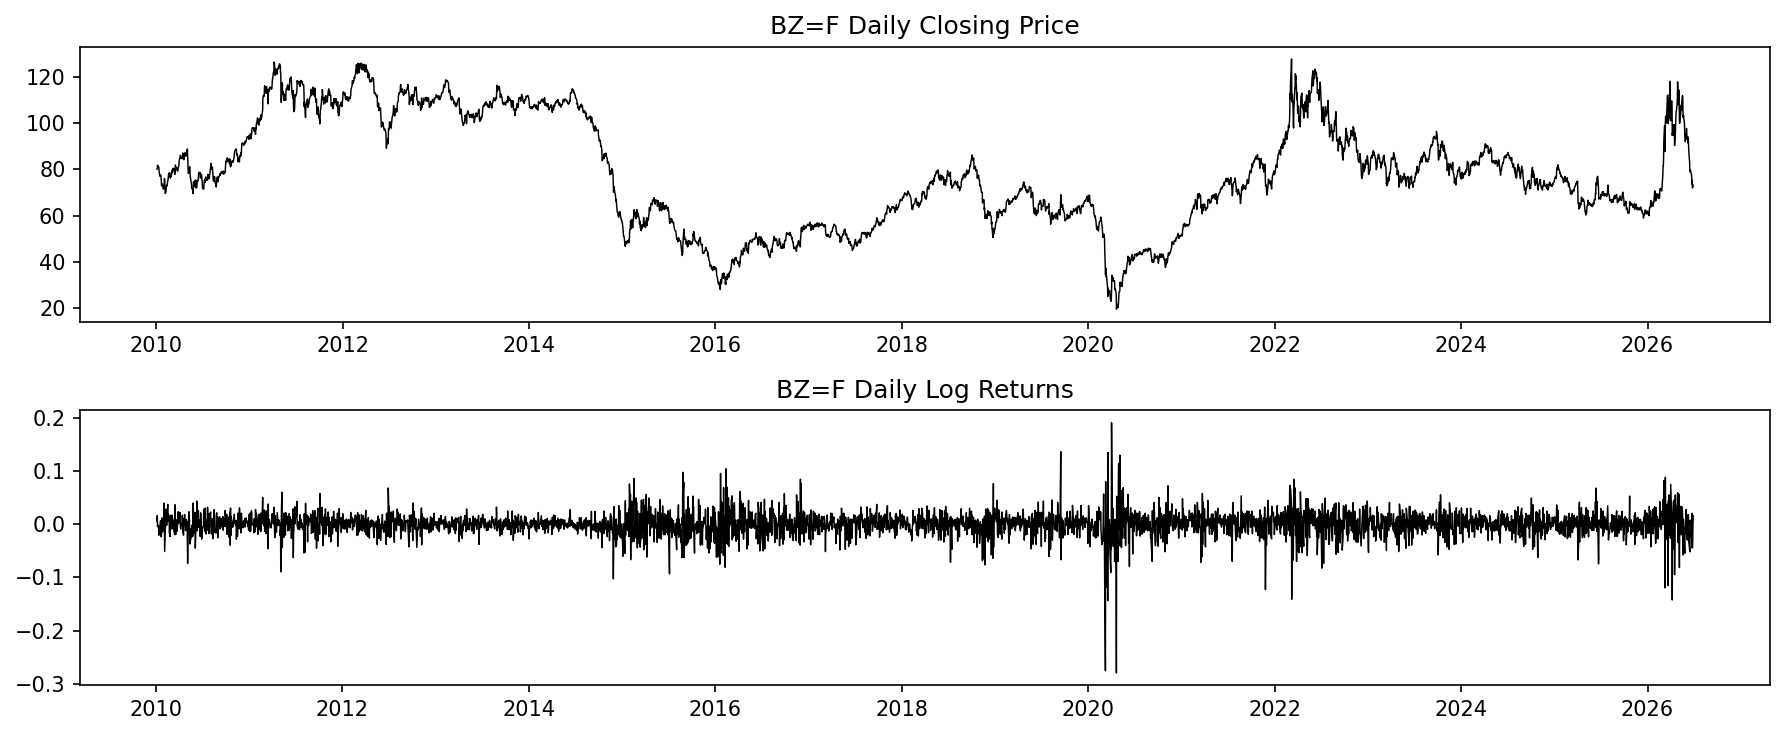

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), dpi=150)
axes[0].plot(close, linewidth=0.7, color='black')
axes[0].set_title(f"{TICKER} Daily Closing Price")
axes[1].plot(returns.index.to_timestamp(), returns.values, linewidth=0.7, color='black')
axes[1].set_title(f"{TICKER} Daily Log Returns")
plt.tight_layout()
plt.show()

In [5]:
# Descriptive statistics of the returns the models are estimated on (roll-adjusted
# when ROLL_HANDLING="adjust"), for the training window, the test window and the
# full sample. Normality is summarised by the dependence-robust Bai-Ng joint test
# (Bai & Ng 2005). Kolmogorov-Smirnov no longer appears here: it assumes i.i.d.
# observations, which daily returns are not; it is kept as a supplementary row in 3.1.
def describe_returns(series, name):
    bn = bai_ng_normality(series)
    return {
        "Sample": name, "count": int(series.count()), "mean": series.mean(),
        "std": series.std(), "min": series.min(), "max": series.max(),
        "skewness": skew(series), "excess kurtosis": kurtosis(series),
        "Bai-Ng joint p": bn["bai_ng_joint_pval"],
    }

stats_df = pd.DataFrame([
    describe_returns(returns[returns.index <= TRAIN_END], "Training window"),
    describe_returns(returns[returns.index >= TEST_START], "Test window"),
    describe_returns(returns, "Full sample"),
]).set_index("Sample")
stats_df


,count,mean,std,min,max,skewness,excess kurtosis,Bai-Ng joint p
Sample,,,,,,,,
Training window,3110,0.000161,0.022898,-0.279761,0.190774,-1.037143,19.469118,0.072752
Test window,1004,0.000053,0.022349,-0.142580,0.088188,-0.707608,3.944001,0.003488
Full sample,4114,0.000135,0.022763,-0.279761,0.190774,-0.961153,15.962174,0.043850


## 3.1 Normality and serial-dependence diagnostics

Daily returns are approximately uncorrelated in the mean (white noise) but *not* independent — they show volatility clustering (strong dependence in squared returns). Under that dependence the i.i.d. KS / Jarque–Bera null distributions are invalid and tend to over-reject. The **main** normality test is therefore Bai & Ng (2005), which replaces the i.i.d. variances of skewness and kurtosis with HAC long-run variances (Layer 2); Layer 1 documents the dependence first. The block-bootstrap KS test (Layer 3), Jarque–Bera and Anderson–Darling are kept as **supplementary** rows (column `role`).

**How to read the dependence tests below.** Each test's H₀ is "no dependence of that kind, up to the tested lag." Rejecting H₀ (p < α) means the data show statistically significant evidence *of* the effect being tested; failing to reject (p > α) means no such evidence was found at that significance level — this does **not** prove the effect is absent, only that this test didn't detect it.

- **Ljung-Box (returns)** — H₀: no autocorrelation in returns (mean is white noise). We *expect* p > α here: if this rejects instead, the mean itself is predictable, which would be a problem for the modelling that follows.
- **Ljung-Box (squared returns)** — H₀: no autocorrelation in squared returns. We *expect* p < α (a rejection) here — this is the volatility-clustering signal that motivates GARCH modelling in the first place.
- **Engle ARCH-LM** — H₀: no ARCH effects (squared returns are not linearly predictable from their own recent lags). Same expectation: p < α confirms ARCH effects are present.


In [6]:
# Layers 1-3 normality / serial-dependence diagnostics (see markdown above).
# Volatility clustering makes the i.i.d. KS test invalid; these address that.
norm_diag = normality_report(returns, name=TICKER, n_boot=N_BOOT, seed=RANDOM_SEED)

# Layer 1 - dependence: mean ~ white noise, variance strongly dependent
# (this is exactly why an i.i.d. distributional test on the levels is invalid).
norm_diag["dependence"].style.format(
    {"statistic": "{:.2f}", "p_value": "{:.2e}"}
).set_caption("Layer 1 - serial dependence: Ljung-Box (returns & squared) + Engle ARCH-LM")

,series,test,lag,statistic,p_value
0,BZ=F,Ljung-Box (returns),10,21.13,2.02e-02
1,BZ=F,Ljung-Box (returns),20,48.02,4.22e-04
2,BZ=F,Ljung-Box (squared returns),10,743.74,2.54e-153
3,BZ=F,Ljung-Box (squared returns),20,1454.16,2.71e-296
4,BZ=F,Engle ARCH-LM,10,414.33,8.39e-83


**How to read the normality tests below.** Every test here shares the same H₀: *the returns are normally distributed.*

- **p < α → reject H₀**: statistically significant evidence *against* normality — the typical, expected finding for daily financial returns (fat tails, occasional skew).
- **p > α → fail to reject H₀**: no evidence against normality was found at this significance level. This does **not** prove normality, only that this particular test could not detect a departure from it.

The **orange** tests (Jarque-Bera, classical KS) assume i.i.d. data — which Layer 1 above shows is violated here — so their p-values are typically **too small** (over-rejection); a rejection there alone is not trustworthy on its own. The **green** tests (Bai-Ng HAC, block-bootstrap KS) stay valid under the dependence just documented, so their p-values are the ones to actually report and interpret.

In [7]:
# Layers 2-3 - normality under dependence. Naive i.i.d. tests (Jarque-Bera,
# classical KS) over-reject; the dependence-robust tests (Bai-Ng HAC joint,
# block-bootstrap KS) plus Anderson-Darling give valid evidence of non-normality.
def _hl_norm(row):
    # Explicit text colour alongside the background: the pastel backgrounds
    # need dark text for contrast, but VS Code's dark theme overrides default
    # text to white, making it unreadable without forcing the colour here.
    a = str(row["assumption"])
    if "robust" in a:
        style = "background-color: #2e7d32; color: #ffffff"   # dependence-robust
    elif "invalid" in a:
        style = "background-color: #bf360c; color: #ffffff"   # i.i.d., invalid here
    else:
        style = ""
    return [style] * len(row)

norm_diag["normality"].style.apply(_hl_norm, axis=1).format(
    {"statistic": "{:.3f}", "p_value": "{:.2e}"}, na_rep="-"
).set_caption("Layers 2-3 - normality: Bai-Ng is the main test (role); i.i.d. tests in orange are invalid here, dependence-robust ones in green")

,series,role,test,assumption,statistic,p_value
0,BZ=F,main,Bai-Ng joint (HAC),dependence-robust,6.254,4.38e-02
1,BZ=F,main,Bai-Ng skewness (HAC),dependence-robust,-1.423,1.55e-01
2,BZ=F,main,Bai-Ng kurtosis (HAC),dependence-robust,2.056,3.98e-02
3,BZ=F,supplementary,Jarque-Bera,i.i.d. (invalid here),44308.854,0.00e+00
4,BZ=F,supplementary,KS vs Normal,i.i.d. (invalid here),0.084,1.82e-25
5,BZ=F,supplementary,KS vs Normal (block-bootstrap),dependence-robust,0.084,9.99e-04
6,BZ=F,supplementary,Anderson-Darling,i.i.d.; crit@5%=0.752,63.531,-


In [8]:
train_returns = returns[returns.index <= TRAIN_END]
test_returns  = returns[(returns.index >= TEST_START) & (returns.index <= TEST_END)]

print(f"Train: {train_returns.index[0]}  →  {train_returns.index[-1]}  ({len(train_returns)} obs)")
print(f"Test:  {test_returns.index[0]}  →  {test_returns.index[-1]}  ({len(test_returns)} obs)")

Train: 2010-01-05  →  2022-06-30  (3110 obs)
Test:  2022-07-01  →  2026-06-29  (1004 obs)


# 4. Classical Econometric Models (GARCH Family)

Five volatility specifications × three error distributions = 15 models.

| Spec | Description |
|------|-------------|
| GARCH | Standard symmetric GARCH(1,1) — Bollerslev (1986) |
| GJR-GARCH | Asymmetric leverage effect via indicator term — Glosten et al. (1993) |
| EGARCH | Log-variance equation, asymmetric leverage term (`o=ASYM_ORDER`) — Nelson (1991) |
| APARCH | Asymmetric power ARCH, leverage term (`o=ASYM_ORDER`) — Ding et al. (1993) |
| FIGARCH | Fractionally integrated long-memory variance — Baillie et al. (1996) |

## 4.1 In-sample fit

In [9]:
insample_models: dict[str, GARCHModel] = {}
ic_rows = []

for model_type, dist in GARCH_SPECS:
    name  = f"{model_type}-{dist.upper()}"
    model = make_garch(model_type, dist, asym_order=ASYM_ORDER)
    try:
        model.fit(train_returns)
        insample_models[name] = model
        row = model.info_criteria()
        row["Model"] = name
        ic_rows.append(row)
    except Exception as exc:
        print(f"  [WARNING] {name} failed: {exc}")

ic_df = (
    pd.DataFrame(ic_rows)
    .set_index("Model")
    .sort_values("BIC")
    [["LogL", "AIC", "BIC"]]
)
print(f"Fitted {len(insample_models)} / {len(GARCH_SPECS)} models")
ic_df

Fitted 10 / 10 models


,LogL,AIC,BIC
Model,,,
EGARCH-T,-6210.334547,12432.669095,12468.923363
APARCH-T,-6212.221768,12438.443537,12480.740183
GJR-GARCH-T,-6219.502522,12451.005044,12487.259312
GARCH-T,-6224.634971,12459.269941,12489.481831
FIGARCH-T,-6222.824601,12457.649202,12493.903470
EGARCH-NORMAL,-6360.933727,12731.867453,12762.079343
APARCH-NORMAL,-6361.599438,12735.198876,12771.453144
GJR-GARCH-NORMAL,-6380.792862,12771.585724,12801.797614
GARCH-NORMAL,-6395.070480,12798.140959,12822.310471


### 4.1.1 Estimated equations and coefficient significance

The information criteria above say which specification fits better, but not *why* — for that the estimated coefficients and their standard errors are needed. This subsection reports them, and in particular lets us check whether the asymmetry (leverage) coefficient is statistically distinguishable from zero: if it is not, an asymmetric specification is effectively equivalent to its symmetric counterpart, which would explain a better in-sample fit that does not translate into better forecasts.

**Reading the tables.** Coefficients are estimated on returns in **percent** (log-returns × 100), the conventional scaling; slope coefficients (α, β, γ, d, φ, δ) are scale-free, while the intercepts (μ, ω) are on the percent scale. Standard errors are in brackets and stars mark significance (\*\*\* p<0.01, \*\* p<0.05, \* p<0.10). An empty cell means the parameter does not exist in that specification (e.g. `gamma[1]` in a symmetric model, `nu` in a Normal one). A companion table below gives the exact p-value for every coefficient instead of just the stars, for citing precise values.

**H₀ for each coefficient** is that the true value is zero. Rejecting it (small p) means the term contributes; failing to reject means the data cannot distinguish that term's effect from zero — which for γ is exactly the "is the asymmetry parameter redundant?" question.

In [10]:
# Estimated coefficients, publication style: "coef (std_err)" with significance stars.
# Empty cell = parameter not present in that specification.
coef_matrix = param_matrix(insample_models)
print(scale_note(insample_models))
print()
coef_matrix

Coefficients are estimated on returns expressed in percent (log-returns x 100), the conventional scaling in the GARCH literature. Slope coefficients (alpha, beta, gamma, d, phi, delta) are scale-free; the intercepts (mu, omega) are on the percent scale. Standard errors in brackets; *** p<0.01, ** p<0.05, * p<0.10.



parameter,mu,omega,alpha[1],gamma[1],beta[1],phi,d,beta,delta,nu
model,,,,,,,,,,
GARCH-NORMAL,0.0383 (0.0307),0.0813** (0.0346),0.1054*** (0.0257),,0.8837*** (0.0270),,,,,
GARCH-T,0.0683** (0.0268),0.0597*** (0.0195),0.0912*** (0.0139),,0.9014*** (0.0143),,,,,4.7277*** (0.4249)
GJR-GARCH-NORMAL,0.0127 (0.0297),0.0863** (0.0378),0.0613*** (0.0173),0.0828** (0.0346),0.8832*** (0.0284),,,,,
GJR-GARCH-T,0.0586** (0.0268),0.0595*** (0.0197),0.0580*** (0.0134),0.0557*** (0.0187),0.9039*** (0.0150),,,,,4.8304*** (0.4451)
EGARCH-NORMAL,-0.0066 (0.0310),0.0369*** (0.0105),0.1842*** (0.0329),-0.0694*** (0.0175),0.9807*** (0.0060),,,,,
EGARCH-T,0.0494* (0.0270),0.0261*** (0.0065),0.1581*** (0.0210),-0.0575*** (0.0114),0.9864*** (0.0037),,,,,4.9538*** (0.4638)
APARCH-NORMAL,-0.0092*** (0.0006),0.0500 (0.0386),0.1001*** (0.0243),0.4790** (0.1862),0.8999*** (0.0326),,,,0.8534 (0.5594),
APARCH-T,0.0545* (0.0279),0.0418 (0.0272),0.0857*** (0.0120),0.3773** (0.1758),0.9143*** (0.0212),,,,1.1713** (0.5501),5.1280*** (0.4738)
FIGARCH-NORMAL,0.0362 (0.0316),0.1907 (0.1366),,,,0.2136 (0.1547),0.4838*** (0.1870),0.5587** (0.2773),,


In [11]:
# Companion table: the exact p-value for every coefficient (not just the
# significance stars above) — useful for citing precise values and for
# borderline cases the *** / ** / * buckets collapse together.
pval_matrix = pvalue_matrix(insample_models, decimals=4)

def _hl_pval(v):
    # same green used for the normality diagnostics, for a consistent and
    # dark-theme-readable "this is significant" signal across the notebook.
    if isinstance(v, (int, float)) and np.isfinite(v) and v < 0.05:
        return "background-color: #2e7d32; color: #ffffff"
    return ""

pval_matrix.style.map(_hl_pval).format(precision=4, na_rep="-").set_caption(
    "Exact p-values per parameter (green = significant at 5%; blank = parameter not in this specification)"
)

parameter,mu,omega,alpha[1],gamma[1],beta[1],phi,d,beta,delta,nu
model,,,,,,,,,,
GARCH-NORMAL,0.2113,0.0189,0.0000,-,0.0000,-,-,-,-,-
GARCH-T,0.0107,0.0022,0.0000,-,0.0000,-,-,-,-,0.0000
GJR-GARCH-NORMAL,0.6689,0.0224,0.0004,0.0165,0.0000,-,-,-,-,-
GJR-GARCH-T,0.0284,0.0025,0.0000,0.0029,0.0000,-,-,-,-,0.0000
EGARCH-NORMAL,0.8322,0.0004,0.0000,0.0001,0.0000,-,-,-,-,-
EGARCH-T,0.0670,0.0001,0.0000,0.0000,0.0000,-,-,-,-,0.0000
APARCH-NORMAL,0.0000,0.1955,0.0000,0.0101,0.0000,-,-,-,0.1271,-
APARCH-T,0.0509,0.1237,0.0000,0.0319,0.0000,-,-,-,0.0332,0.0000
FIGARCH-NORMAL,0.2515,0.1628,-,-,-,0.1675,0.0097,0.0439,-,-


In [12]:
# Is the asymmetry (leverage) parameter redundant? Direct per-model verdict.
# NOTE: models reported as "no asymmetry parameter estimated" have no gamma in
# their fitted parameter vector, so they are symmetric AS CONFIGURED — worth
# checking against what each specification is intended to capture.
asym_df = asymmetry_summary(insample_models, alpha=0.05)

_n_asym = int(asym_df["has_asymmetry"].sum())
_n_sig = int(asym_df["significant"].sum())
print(f"Models with an estimated asymmetry parameter: {_n_asym} / {len(asym_df)}")
print(f"  of which significant at 5%: {_n_sig}")
print()

asym_df[["has_asymmetry", "coef", "std_err", "t_stat", "p_value", "significant", "verdict"]]

Models with an estimated asymmetry parameter: 6 / 10
  of which significant at 5%: 6



,has_asymmetry,coef,std_err,t_stat,p_value,significant,verdict
GARCH-NORMAL,False,NaN,NaN,NaN,NaN,False,no asymmetry parameter estimated
GARCH-T,False,NaN,NaN,NaN,NaN,False,no asymmetry parameter estimated
GJR-GARCH-NORMAL,True,0.082828,0.034555,2.396993,0.01653,True,leverage effect supported
GJR-GARCH-T,True,0.055724,0.018692,2.981116,0.002872,True,leverage effect supported
EGARCH-NORMAL,True,-0.069373,0.017474,-3.970154,0.000072,True,leverage effect supported
EGARCH-T,True,-0.057517,0.011359,-5.063491,0.0,True,leverage effect supported
APARCH-NORMAL,True,0.478983,0.186167,2.57287,0.010086,True,leverage effect supported
APARCH-T,True,0.377309,0.175843,2.145711,0.031896,True,leverage effect supported
FIGARCH-NORMAL,False,NaN,NaN,NaN,NaN,False,no asymmetry parameter estimated
FIGARCH-T,False,NaN,NaN,NaN,NaN,False,no asymmetry parameter estimated


In [13]:
# Volatility persistence, using the measure appropriate to each specification
# (alpha+beta for GARCH, alpha+beta+gamma/2 for GJR, beta for EGARCH's log-variance
# AR, and the long-memory parameter d for FIGARCH). Values are comparable only
# within the same measure.
persistence(insample_models)

,measure,value
GARCH-NORMAL,alpha+beta,0.989053
GARCH-T,alpha+beta,0.992617
GJR-GARCH-NORMAL,alpha+beta+gamma/2,0.985969
GJR-GARCH-T,alpha+beta+gamma/2,0.989773
EGARCH-NORMAL,beta (log-variance AR),0.980736
EGARCH-T,beta (log-variance AR),0.986435
APARCH-NORMAL,n/a (no closed form),NaN
APARCH-T,n/a (no closed form),NaN
FIGARCH-NORMAL,d (long memory),0.483766
FIGARCH-T,d (long memory),0.472806


In [14]:
# Fitted mean and variance equations, with the estimated coefficients substituted.
# The variance equation shown reflects the specification AS ESTIMATED — an
# asymmetry term appears only where an asymmetry coefficient was actually fitted.
from IPython.display import Markdown, display

display(Markdown(equations_markdown(insample_models, decimals=4)))

$$\begin{aligned} \textbf{GARCH-NORMAL} \\[2pt] r_t = 0.0383 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim \mathcal{N}(0,1) \\[2pt] \sigma_t^2 = 0.0813 + 0.1054\,\varepsilon_{t-1}^2 + 0.8837\,\sigma_{t-1}^2 \end{aligned}$$

$$\begin{aligned} \textbf{GARCH-T} \\[2pt] r_t = 0.0683 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim t_{\nu} \\[2pt] \sigma_t^2 = 0.0597 + 0.0912\,\varepsilon_{t-1}^2 + 0.9014\,\sigma_{t-1}^2 \\[2pt] \nu = 4.7277 \end{aligned}$$

$$\begin{aligned} \textbf{GJR-GARCH-NORMAL} \\[2pt] r_t = 0.0127 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim \mathcal{N}(0,1) \\[2pt] \sigma_t^2 = 0.0863 + 0.0613\,\varepsilon_{t-1}^2 + 0.0828\,\varepsilon_{t-1}^2\,\mathbb{1}_{\{\varepsilon_{t-1} < 0\}} + 0.8832\,\sigma_{t-1}^2 \end{aligned}$$

$$\begin{aligned} \textbf{GJR-GARCH-T} \\[2pt] r_t = 0.0586 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim t_{\nu} \\[2pt] \sigma_t^2 = 0.0595 + 0.0580\,\varepsilon_{t-1}^2 + 0.0557\,\varepsilon_{t-1}^2\,\mathbb{1}_{\{\varepsilon_{t-1} < 0\}} + 0.9039\,\sigma_{t-1}^2 \\[2pt] \nu = 4.8304 \end{aligned}$$

$$\begin{aligned} \textbf{EGARCH-NORMAL} \\[2pt] r_t = -0.0066 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim \mathcal{N}(0,1) \\[2pt] \ln \sigma_t^2 = 0.0369 + 0.1842\left(|z_{t-1}| - \mathbb{E}|z_{t-1}|\right) - 0.0694\,z_{t-1} + 0.9807\,\ln \sigma_{t-1}^2 \end{aligned}$$

$$\begin{aligned} \textbf{EGARCH-T} \\[2pt] r_t = 0.0494 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim t_{\nu} \\[2pt] \ln \sigma_t^2 = 0.0261 + 0.1581\left(|z_{t-1}| - \mathbb{E}|z_{t-1}|\right) - 0.0575\,z_{t-1} + 0.9864\,\ln \sigma_{t-1}^2 \\[2pt] \nu = 4.9538 \end{aligned}$$

$$\begin{aligned} \textbf{APARCH-NORMAL} \\[2pt] r_t = -0.0092 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim \mathcal{N}(0,1) \\[2pt] \sigma_t^{0.8534} = 0.0500 + 0.1001\,\left(|\varepsilon_{t-1}| - 0.4790\,\varepsilon_{t-1}\right)^{0.8534} + 0.8999\,\sigma_{t-1}^{0.8534} \end{aligned}$$

$$\begin{aligned} \textbf{APARCH-T} \\[2pt] r_t = 0.0545 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim t_{\nu} \\[2pt] \sigma_t^{1.1713} = 0.0418 + 0.0857\,\left(|\varepsilon_{t-1}| - 0.3773\,\varepsilon_{t-1}\right)^{1.1713} + 0.9143\,\sigma_{t-1}^{1.1713} \\[2pt] \nu = 5.1280 \end{aligned}$$

$$\begin{aligned} \textbf{FIGARCH-NORMAL} \\[2pt] r_t = 0.0362 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim \mathcal{N}(0,1) \\[2pt] \sigma_t^2 = 0.1907 + 0.5587\,\sigma_{t-1}^2 + \left[1 - 0.5587L - (1 - 0.2136L)(1-L)^{0.4838}\right]\varepsilon_t^2 \end{aligned}$$

$$\begin{aligned} \textbf{FIGARCH-T} \\[2pt] r_t = 0.0658 + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim t_{\nu} \\[2pt] \sigma_t^2 = 0.1557 + 0.5875\,\sigma_{t-1}^2 + \left[1 - 0.5875L - (1 - 0.2340L)(1-L)^{0.4728}\right]\varepsilon_t^2 \\[2pt] \nu = 4.7203 \end{aligned}$$

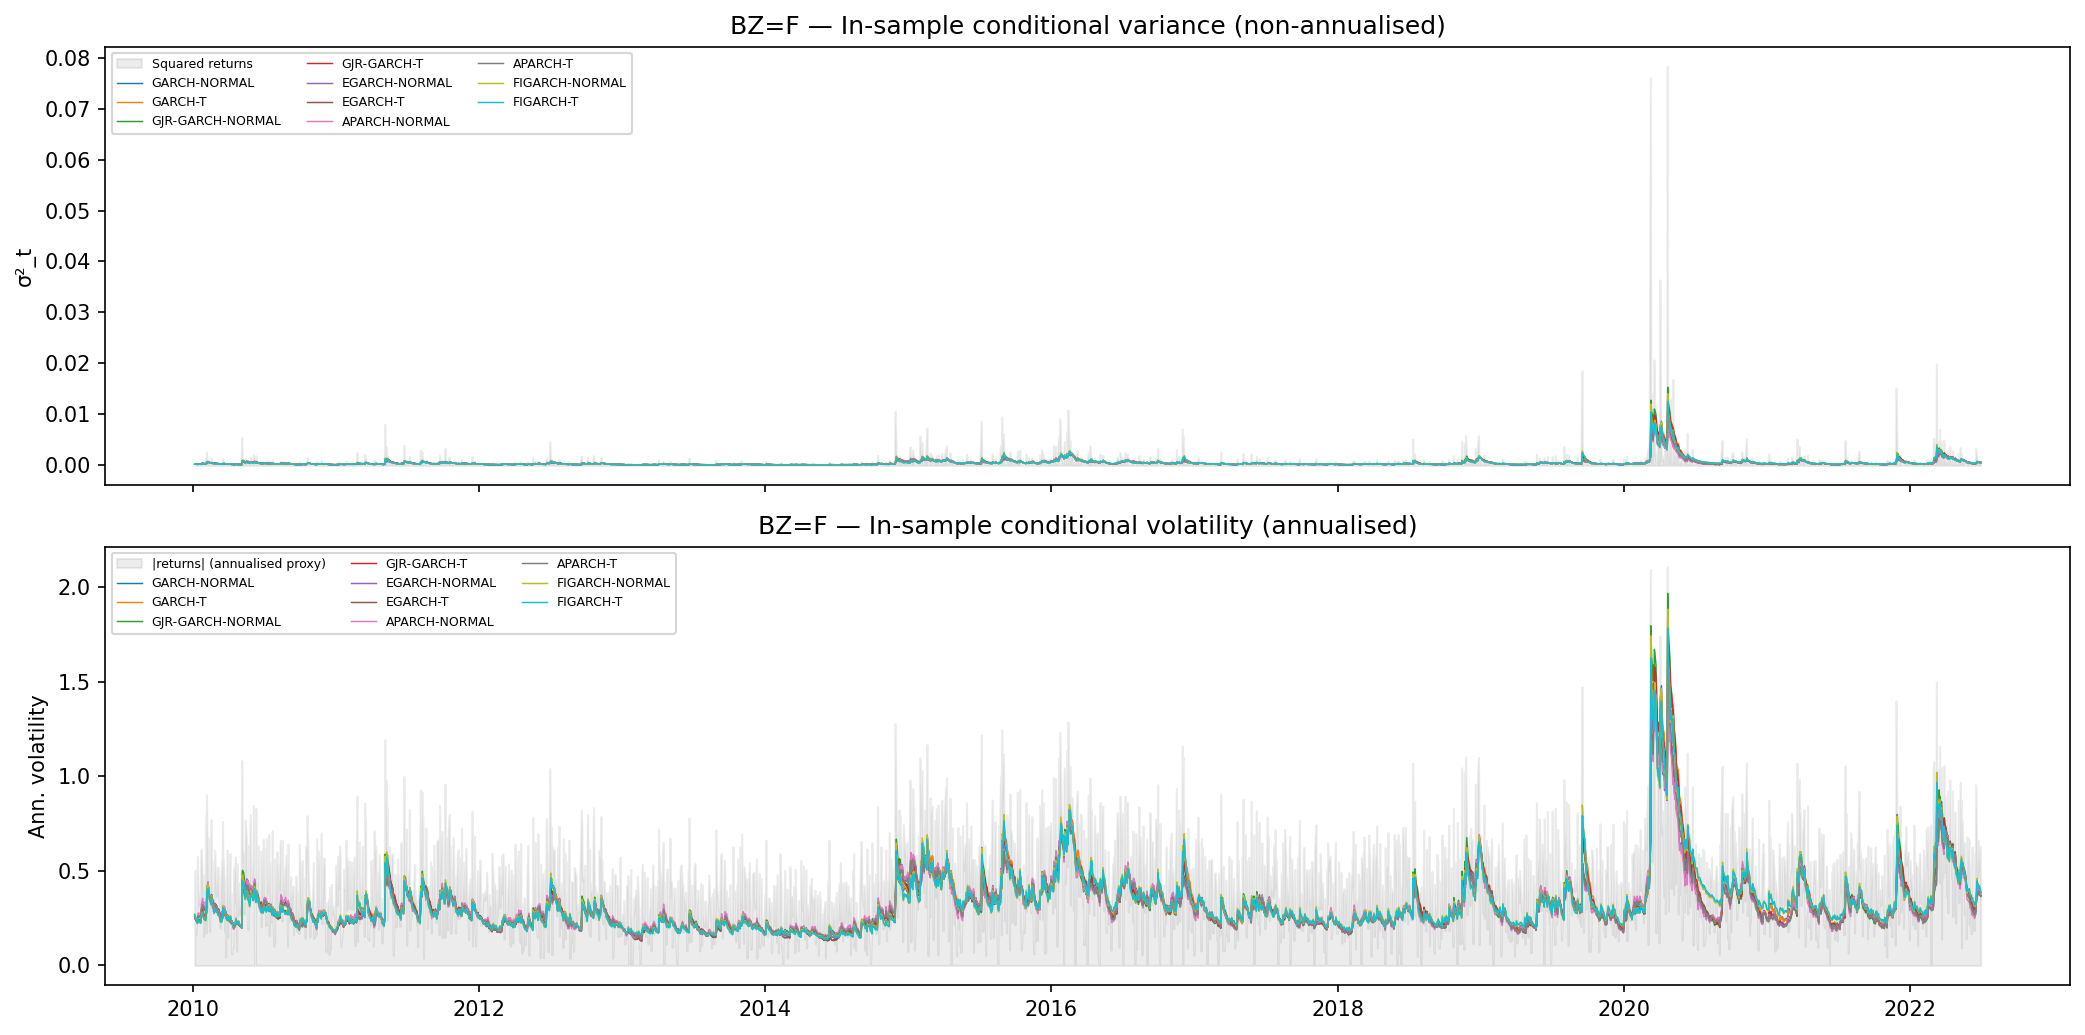

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), dpi=150, sharex=True)

# Raw variance
axes[0].fill_between(
    train_returns.index.to_timestamp(),
    train_returns.values ** 2,
    alpha=0.15, color="gray", label="Squared returns",
)
for name, model in insample_models.items():
    cv = model.insample_variance()
    axes[0].plot(cv.index.to_timestamp(), cv.values, linewidth=0.7, label=name)
axes[0].set_title(f"{TICKER} — In-sample conditional variance (non-annualised)")
axes[0].set_ylabel("σ²_t")
axes[0].legend(fontsize=6, ncol=3)

# Annualised volatility
axes[1].fill_between(
    train_returns.index.to_timestamp(),
    np.sqrt(np.abs(train_returns.values) * np.sqrt(252)),
    alpha=0.15, color="gray", label="|returns| (annualised proxy)",
)
for name, model in insample_models.items():
    cv = model.insample_variance()
    axes[1].plot(cv.index.to_timestamp(), np.sqrt(cv.values * 252), linewidth=0.7, label=name)
axes[1].set_title(f"{TICKER} — In-sample conditional volatility (annualised)")
axes[1].set_ylabel("Ann. volatility")
axes[1].legend(fontsize=6, ncol=3)

plt.tight_layout()
plt.show()

### 4.1.2 Distributional diagnostics on the standardized residuals

Section 3.1 tested the **returns** for normality. That describes the *unconditional* distribution, and on its own it cannot justify the choice of innovation distribution made here: with $r_t = \sqrt{h_t}\,z_t$, a time-varying $h_t$ makes the returns fat-tailed **even when every $z_t$ is exactly Gaussian**. The assumption each specification actually makes is about the standardized residuals $z_t = (r_t - \hat\mu)/\sqrt{h_t}$.

**Main table** — what the article reports:

- **Adequacy of the model** — `LB(20) p` (Ljung–Box on $z_t$, mean equation), `LB2(20) p` (Ljung–Box on $z_t^2$) and `ARCH-LM p` (variance equation). A well-specified model leaves no dependence, so **large p-values are the good outcome**. A rejection means the equation is misspecified.
- **Adequacy of the model's own innovation distribution** — the probability integral transform $u_t = F(z_t;\hat\theta)$ under each model's fitted distribution (Diebold, Günther & Tay 1998), tested for uniformity by **Anderson–Darling** (`PIT AD`, `PIT AD p`). Anderson–Darling weights the tails, which is where Normal and $t$ differ. Under correct specification $u_t$ is i.i.d. $U(0,1)$, so the p-value comes from the exact null of a fully specified uniform sample, simulated by Monte Carlo (10,000 draws, floor $10^{-4}$). It is slightly conservative because the $t$ shape parameter is estimated. **Large p is the good outcome.**

**Supplementary table** — kept for reference, not in the main text: the shape of $z_t$ (`skew`, `ex.kurt`), the Normal-null battery on $z_t$ (`BaiNg p`, `KS-N p` with a block-bootstrap p-value, `AD-N`), and Kolmogorov–Smirnov on the PIT (`PIT KS p`, block bootstrap).

`nu` is the fitted degrees of freedom of $t$; blank for Normal.


In [16]:
# Layer 4 - the tests applied where the distributional assumption actually lives:
# the standardized residuals of each fitted model, and a probability-integral
# transform under each model's OWN innovation distribution.
ALPHA_DIST = 0.05  # significance level for the verdicts below

resid_diag = residual_diagnostics_table(
    insample_models, lb_lag=20, n_boot=N_BOOT, seed=RANDOM_SEED
)
resid_main = resid_diag[resid_diag.attrs["main_columns"]]
resid_supp = resid_diag[resid_diag.attrs["supplementary_columns"]]

def _hl_resid(col):
    # Explicit text colour alongside the background: VS Code's dark theme
    # overrides default text to white, which is unreadable on pastel fills.
    ok, bad = "background-color: #2e7d32; color: #ffffff", "background-color: #bf360c; color: #ffffff"
    if col.name in ("LB(20) p", "LB2(20) p", "ARCH-LM p", "PIT AD p", "PIT KS p"):
        # model / distribution adequacy: LARGE p is the good outcome
        return [ok if v > ALPHA_DIST else bad for v in col]
    if col.name in ("BaiNg p", "KS-N p"):
        # normality of z_t: a rejection is evidence AGAINST Normal innovations
        return [bad if v < ALPHA_DIST else ok for v in col]
    return [""] * len(col)

print(f"Standardized residuals of {len(insample_models)} models fitted on the training window")
print(f"green = the model's assumption survives this test; orange = it is rejected (alpha={ALPHA_DIST})")
display(resid_main.style.apply(_hl_resid, axis=0).format(
    {"nu": "{:.3f}", "LB(20) p": "{:.3f}", "LB2(20) p": "{:.3f}", "ARCH-LM p": "{:.3f}",
     "PIT AD": "{:.3f}", "PIT AD p": "{:.4f}"},
    na_rep="-",
).set_caption("Main - model adequacy (Ljung-Box, ARCH-LM) and the PIT under each model's own "
              "distribution, decided by Anderson-Darling (Monte Carlo p-value)"))

print("Supplementary - not in the article's main text")
resid_supp.style.apply(_hl_resid, axis=0).format(
    {"skew": "{:+.3f}", "ex.kurt": "{:.3f}", "BaiNg p": "{:.2e}", "KS-N p": "{:.3f}",
     "AD-N": "{:.2f}", "PIT KS p": "{:.3f}"},
    na_rep="-",
).set_caption("Supplementary - shape of z_t, Normal-null tests on z_t, and Kolmogorov-Smirnov on the PIT")


Standardized residuals of 10 models fitted on the training window
green = the model's assumption survives this test; orange = it is rejected (alpha=0.05)


,dist,nu,n,LB(20) p,LB2(20) p,ARCH-LM p,PIT AD,PIT AD p
model,,,,,,,,
GARCH-NORMAL,normal,-,3110,0.894,0.991,0.928,17.402,0.0001
GARCH-T,t,4.728,3110,0.908,0.986,0.883,1.634,0.1474
GJR-GARCH-NORMAL,normal,-,3110,0.901,0.996,0.948,16.899,0.0001
GJR-GARCH-T,t,4.830,3110,0.922,0.991,0.912,1.483,0.1793
EGARCH-NORMAL,normal,-,3110,0.927,0.982,0.815,16.800,0.0001
EGARCH-T,t,4.954,3110,0.940,0.928,0.563,1.651,0.1443
APARCH-NORMAL,normal,-,3110,0.911,0.969,0.673,15.994,0.0001
APARCH-T,t,5.128,3110,0.923,0.935,0.552,1.619,0.1501
FIGARCH-NORMAL,normal,-,3110,0.927,0.995,0.915,18.417,0.0001


Supplementary - not in the article's main text


,skew,ex.kurt,BaiNg p,KS-N p,AD-N,PIT KS p
model,,,,,,
GARCH-NORMAL,-0.621,4.709,1.52e-04,0.001,18.52,0.001
GARCH-T,-0.638,4.771,1.30e-04,0.001,18.53,0.537
GJR-GARCH-NORMAL,-0.573,4.487,2.44e-04,0.001,17.45,0.001
GJR-GARCH-T,-0.600,4.564,1.38e-04,0.001,17.62,0.391
EGARCH-NORMAL,-0.578,4.109,7.52e-05,0.001,16.63,0.001
EGARCH-T,-0.603,4.244,7.91e-05,0.001,16.82,0.213
APARCH-NORMAL,-0.570,4.048,1.05e-04,0.001,16.62,0.001
APARCH-T,-0.586,4.293,1.36e-04,0.001,16.74,0.288
FIGARCH-NORMAL,-0.616,4.871,3.00e-04,0.001,18.64,0.001


**Detailed battery for the best-fitting specification.** The table above compresses each test to a single number; the three tables below show the full battery for the model that information criteria select, so the individual statistics can be cited.

The `adequacy` table is the variance-equation check — here a **large** p-value is the good outcome. The `normality` table asks whether the Normal innovation assumption holds for $z_t$; as in Section 3.1, the dependence-robust rows (Bai–Ng HAC, block-bootstrap KS) are the ones to report, though after GARCH filtering the i.i.d. rows are far less objectionable than they were on raw returns, since most of the dependence has been removed. The `pit` table asks whether this model's **own** fitted distribution is adequate: Anderson–Darling with its Monte Carlo p-value is the main row, the two KS rows are supplementary.

Note on resolution: a block-bootstrap p-value cannot fall below $1/(B+1)$, and the Monte Carlo PIT p-value not below $1/10001$, so a reported value equal to that floor means "smaller than this bootstrap can resolve", not exactly that number.

In [17]:
# Full battery for the specification selected by BIC.
best_ic_name  = ic_df.index[0]
best_ic_model = insample_models[best_ic_name]

resid_rep = residual_report(
    best_ic_model.std_resid,
    name=best_ic_name,
    pit=best_ic_model.pit(),
    dist_label=best_ic_model.dist,
    n_boot=N_BOOT,
    seed=RANDOM_SEED,
)

shape = best_ic_model.dist_params
print(f"Best by BIC: {best_ic_name}"
      + (f"   ({', '.join(f'{k}={v:.3f}' for k, v in shape.items())})" if shape else ""))
print(f"p-value floors: block bootstrap (KS) {1 / (N_BOOT + 1):.2e}; Monte Carlo (PIT AD) {1 / 10001:.2e}")
print("role = main: reported in the article; role = supplementary: kept for reference")
for key, title in [("adequacy",  "variance equation - large p is GOOD (no ARCH left in z_t)"),
                   ("normality", "is the NORMAL assumption adequate for z_t?"),
                   ("pit",       "is this model's OWN fitted distribution adequate? large p is GOOD")]:
    print(f"\n--- {key}: {title} ---")
    print(resid_rep[key].to_string(index=False))

Best by BIC: EGARCH-T   (nu=4.954)
p-value floors: block bootstrap (KS) 9.99e-04; Monte Carlo (PIT AD) 1.00e-04
role = main: reported in the article; role = supplementary: kept for reference

--- adequacy: variance equation - large p is GOOD (no ARCH left in z_t) ---
   model role                               test  lag  statistic  p_value
EGARCH-T main         Ljung-Box (std. residuals)   10   4.846686 0.901181
EGARCH-T main         Ljung-Box (std. residuals)   20  11.244022 0.939647
EGARCH-T main Ljung-Box (squared std. residuals)   10   8.724124 0.558470
EGARCH-T main Ljung-Box (squared std. residuals)   20  11.624608 0.928391
EGARCH-T main                      Engle ARCH-LM   10   8.681463 0.562577

--- normality: is the NORMAL assumption adequate for z_t? ---
   model          role                           test            assumption   statistic      p_value
EGARCH-T supplementary                    Jarque-Bera                i.i.d. 2522.651001 0.000000e+00
EGARCH-T supplementary 

## 4.2 Out-of-sample evaluation

Window scheme controlled by `WINDOW_TYPE` (expanding or sliding), 1-step-ahead.  
Parameters re-estimated every `REFIT_EVERY` steps.  
Realized variance proxy controlled by `VARIANCE_PROXY` (default: Garman-Klass).

In [18]:
evaluator = RollingEvaluator(
    n_ahead=N_AHEAD, refit_every=REFIT_EVERY,
    window_type=WINDOW_TYPE, window_size=WINDOW_SIZE,
)

# functools.partial is picklable — required when PARALLEL_JOBS != 1.
# lambda would work for sequential (n_jobs=1) but cannot be sent to worker processes.
garch_eval_specs = [
    (partial(make_garch, t, d, asym_order=ASYM_ORDER), f"{t}-{d.upper()}")
    for t, d in GARCH_SPECS
]

garch_results: dict[str, ForecastResult] = evaluator.evaluate_many(
    garch_eval_specs, train_returns, test_returns,
    actuals_series=variance_proxy,
    # train_target_series deliberately not passed: GARCH is estimated
    # by QMLE on returns and has no regression target to redirect.
    verbose=True, n_jobs=PARALLEL_JOBS,
)
_width = WINDOW_SIZE if (WINDOW_TYPE == "sliding" and WINDOW_SIZE is not None) else (
    len(train_returns) if WINDOW_TYPE == "sliding" else "n/a"
)
print(f"\nCompleted {len(garch_results)} GARCH models.")
print(f"Window type: {WINDOW_TYPE}  |  Window size: {_width}  |  Proxy: {VARIANCE_PROXY}")

Parallel evaluation: 10 models on 10 worker process(es)...
  [GARCH-NORMAL] done  RMSE=2.2567e-03
  [EGARCH-NORMAL] done  RMSE=2.2723e-03
  [GJR-GARCH-NORMAL] done  RMSE=2.2527e-03
  [GARCH-T] done  RMSE=2.2541e-03
  [EGARCH-T] done  RMSE=2.2751e-03
  [GJR-GARCH-T] done  RMSE=2.2541e-03
  [APARCH-NORMAL] done  RMSE=2.2358e-03
  [APARCH-T] done  RMSE=2.2447e-03
  [FIGARCH-NORMAL] done  RMSE=2.2575e-03
  [FIGARCH-T] done  RMSE=2.2576e-03

Completed 10 GARCH models.
Window type: sliding  |  Window size: 750  |  Proxy: garman_klass_overnight


In [19]:
garch_metrics_df = (
    pd.DataFrame({name: r.metrics() for name, r in garch_results.items()})
    .T
    .sort_values("RMSE")
    [["RMSE", "MAE", "MSE", "QLIKE"]]
)
garch_metrics_df

,RMSE,MAE,MSE,QLIKE
APARCH-NORMAL,0.002236,0.000432,0.000005,-6.691890
APARCH-T,0.002245,0.000435,0.000005,-6.677467
GJR-GARCH-NORMAL,0.002253,0.000424,0.000005,-6.645706
GJR-GARCH-T,0.002254,0.000417,0.000005,-6.643661
GARCH-T,0.002254,0.000416,0.000005,-6.664218
GARCH-NORMAL,0.002257,0.000421,0.000005,-6.659473
FIGARCH-NORMAL,0.002258,0.000417,0.000005,-6.657297
FIGARCH-T,0.002258,0.000417,0.000005,-6.659338
EGARCH-NORMAL,0.002272,0.000430,0.000005,-6.575636
EGARCH-T,0.002275,0.000427,0.000005,-6.551823


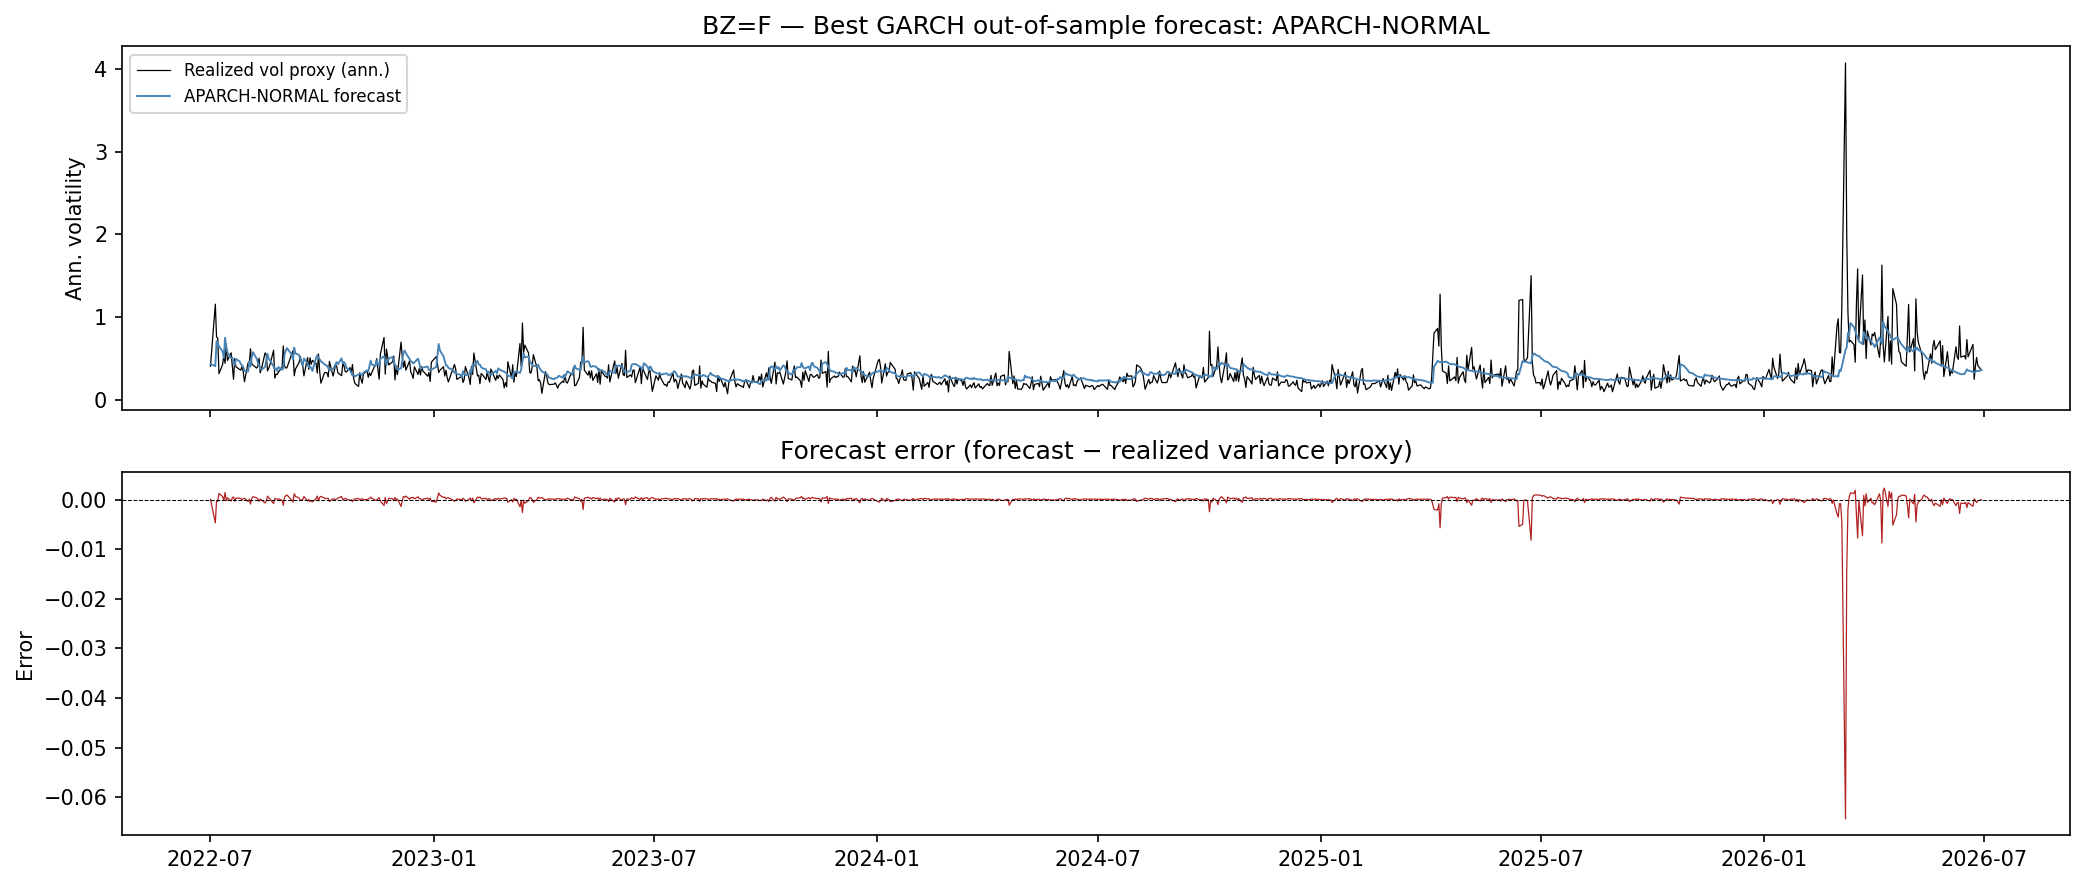

In [20]:
best_garch_name = garch_metrics_df.index[0]
r = garch_results[best_garch_name]

fig, axes = plt.subplots(2, 1, figsize=(14, 6), dpi=150, sharex=True)
axes[0].plot(r.actuals.index.to_timestamp(), np.sqrt(r.actuals.values * 252),
             color='black', linewidth=0.6, label='Realized vol proxy (ann.)')
axes[0].plot(r.forecasts.index.to_timestamp(), np.sqrt(r.forecasts.values * 252),
             color='steelblue', linewidth=0.9, label=f'{best_garch_name} forecast')
axes[0].set_title(f"{TICKER} — Best GARCH out-of-sample forecast: {best_garch_name}")
axes[0].set_ylabel("Ann. volatility")
axes[0].legend(fontsize=8)
axes[1].plot(r.errors.index.to_timestamp(), r.errors.values, color='firebrick', linewidth=0.6)
axes[1].axhline(0, color='black', linewidth=0.5, linestyle='--')
axes[1].set_title("Forecast error (forecast − realized variance proxy)")
axes[1].set_ylabel("Error")
plt.tight_layout()
plt.show()

### 4.2.1 Equal-weight combination of the GARCH family

The arithmetic mean of the one-step variance forecasts of the GARCH specifications in `COMBINER_GARCH_SPECS` — the same forecasts the combiners receive. The forecast-combination literature finds the simple average hard to beat with estimated weights (Bates & Granger 1969; Timmermann 2006), which makes it the natural benchmark for the combiners: the question is whether the ML model extracts from the GARCH family anything the average does not. Computed from the GARCH results above; nothing is re-estimated.


In [21]:
ew_results: dict[str, ForecastResult] = {}
if GARCH_EW:
    _ew_members = [f"{t}-{d.upper()}" for t, d in COMBINER_GARCH_SPECS]
    ew_results = {"GARCH-EW": equal_weight_combination(garch_results, _ew_members, name="GARCH-EW")}
    _q = {n: r.metrics()["QLIKE"] for n, r in garch_results.items()}
    _best = min(_q, key=_q.get)
    _ew = ew_results["GARCH-EW"].metrics()
    print(f"GARCH-EW, mean of {len(_ew_members)} specifications: QLIKE = {_ew['QLIKE']:.6f}   RMSE = {_ew['RMSE']:.6e}")
    print(f"Best single GARCH by QLIKE: {_best}   QLIKE = {_q[_best]:.6f}")
    print(f"GARCH-EW ranks {sorted([*_q.values(), _ew['QLIKE']]).index(_ew['QLIKE']) + 1} of "
          f"{len(_q) + 1} on QLIKE among the GARCH family plus the average")
else:
    print("GARCH_EW = False - equal-weight benchmark skipped.")


GARCH-EW, mean of 10 specifications: QLIKE = -6.662580   RMSE = 2.254300e-03
Best single GARCH by QLIKE: APARCH-NORMAL   QLIKE = -6.691890
GARCH-EW ranks 4 of 11 on QLIKE among the GARCH family plus the average


## 4.3 Realized GARCH (Hansen, Huang & Shek 2012)

Every specification in 4.1–4.2 is estimated by QMLE on close-to-close returns, so the only thing it ever learns about day $t$ is $r_t$. The ML models in the sections below are trained on a range-based proxy and therefore also see the daily high–low range. That is what makes "ML beats GARCH" ambiguous as a claim: part of any gap is the **model class** and part is simply the richer **information set**, and a comparison between the two groups as they stand cannot separate them.

Realized GARCH closes that gap from the other side — a GARCH model that also observes the realized measure $x_t$:

$$\log h_t = \omega + \beta \log h_{t-1} + \gamma \log x_{t-1}$$
$$\log x_t = \xi + \varphi \log h_t + \tau(z_t) + u_t, \qquad \tau(z) = \tau_1 z + \tau_2(z^2-1)$$

The **measurement equation** is what makes this more than a GARCH with an extra regressor: it states explicitly how the noisy observable $x_t$ relates to the latent $h_t$, which is what allows both equations to be estimated jointly rather than plugging $x_t$ in as though it were exact. Persistence is $\beta + \varphi\gamma$, not $\beta$.

**Which realized measure.** Any per-day proxy, set by `REALIZED_GARCH_SPECS`; each choice is a different model and gets its own row. Yang–Zhang cannot serve — it is a multi-day estimator, so a rolling YZ at date $t$ is the average variance over the preceding window rather than day $t$'s variance. $\varphi$ would absorb the smoothing, $u_t$ would be heavily autocorrelated in violation of its own assumption, and the premise that $x_t$ is a sharper signal of $h_t$ than $r_t^2$ would be lost.

**Reading the likelihood.** The *joint* likelihood scores both equations, so it is **not** comparable with the return-only likelihood of a plain GARCH — it is evaluating a different number of observed series. The table below reports the **partial** (return-equation) likelihood, which is comparable, and still charges all eight parameters against it; that is the conservative direction, and it cannot flatter this model relative to section 4.1. Returns are scaled by 100 exactly as in 4.1 — without that the two sets of log-likelihoods would differ by about $n\log 100 \approx 14{,}300$ for purely dimensional reasons.

In [22]:
# In-sample fit, one model per realized measure. Kept in its own dict rather
# than merged into `insample_models`: that dict feeds param_matrix() and the
# residual diagnostics in 4.1.x, neither of which applies to this model.
realized_models: dict[str, RealizedGARCH] = {}
rg_rows = []

for _rm in REALIZED_GARCH_SPECS:
    _name = f"RealGARCH-{_rm}"
    try:
        _m = RealizedGARCH(realized_measures[_rm], floor_q=REALGARCH_FLOOR_Q).fit(train_returns)
        realized_models[_name] = _m
        _p, _ic = _m.params, _m.info_criteria()
        rg_rows.append({
            "Model": _name, "beta": _p["beta"], "gamma": _p["gamma"],
            "phi": _p["phi"], "xi": _p["xi"], "tau1": _p["tau1"],
            "tau2": _p["tau2"], "sigma_u": _p["sigma_u"],
            "persistence": _m.persistence,
            "LogL": _ic["LogL"], "BIC": _ic["BIC"], "LogL_joint": _ic["LogL_joint"],
        })
    except Exception as exc:
        print(f"  [WARNING] {_name} failed: {exc}")

if rg_rows:
    rg_df = pd.DataFrame(rg_rows).set_index("Model")
    _best_garch_bic = ic_df["BIC"].min()
    print(f"Best GARCH BIC (section 4.1): {_best_garch_bic:.1f}   "
          f"[{ic_df['BIC'].idxmin()}]")
    print("LogL/BIC below are PARTIAL (return equation only), so they sit on the")
    print("same footing as section 4.1; LogL_joint additionally scores the")
    print("measurement equation and is NOT comparable with it.")
    display(rg_df.round(4))
else:
    print("No Realized GARCH models fitted (REALIZED_GARCH_SPECS is empty).")

Best GARCH BIC (section 4.1): 12468.9   [EGARCH-T]
LogL/BIC below are PARTIAL (return equation only), so they sit on the
same footing as section 4.1; LogL_joint additionally scores the
measurement equation and is NOT comparable with it.


,beta,gamma,phi,xi,tau1,tau2,sigma_u,persistence,LogL,BIC,LogL_joint
Model,,,,,,,,,,,
RealGARCH-garman_klass_overnight,0.8601,0.1285,0.9848,-0.5072,-0.0383,0.1625,1.0227,0.9867,-6362.6537,12789.6464,-10845.455


In [23]:
# Out-of-sample, through the same evaluator as every other model group.
# The realized measure travels with the factory, not through the evaluator:
# it defines WHICH model this is, so train_target_series is deliberately not
# passed here — the notebook's ML training target must not redefine it.
realized_eval_specs = [
    (partial(make_realized_garch, realized_measures[_rm], floor_q=REALGARCH_FLOOR_Q), f"RealGARCH-{_rm}")
    for _rm in REALIZED_GARCH_SPECS
]

realized_results: dict[str, ForecastResult] = evaluator.evaluate_many(
    realized_eval_specs, train_returns, test_returns,
    actuals_series=variance_proxy,
    verbose=True, n_jobs=PARALLEL_JOBS,
) if realized_eval_specs else {}

if realized_results:
    _rg_metrics = (
        pd.DataFrame({n: r.metrics() for n, r in realized_results.items()})
        .T[["RMSE", "MAE", "MSE", "QLIKE"]]
        .sort_values("QLIKE")
    )
    _best_garch = min(garch_results, key=lambda n: garch_results[n].metrics()["QLIKE"])
    _bg = garch_results[_best_garch].metrics()
    print(f"\nBest plain GARCH out-of-sample: {_best_garch}  "
          f"QLIKE={_bg['QLIKE']:.6f}  RMSE={_bg['RMSE']:.6e}")
    print("A Realized GARCH beating it isolates the value of the RANGE information")
    print("inside one model class — the same information the ML models are trained on.")
    display(_rg_metrics)

Parallel evaluation: 1 models on 10 worker process(es)...
  [RealGARCH-garman_klass_overnight] done  RMSE=2.2597e-03

Best plain GARCH out-of-sample: APARCH-NORMAL  QLIKE=-6.691890  RMSE=2.235818e-03
A Realized GARCH beating it isolates the value of the RANGE information
inside one model class — the same information the ML models are trained on.


,RMSE,MAE,MSE,QLIKE
RealGARCH-garman_klass_overnight,0.00226,0.000404,0.000005,-6.678152


# 5. Standalone XGBoost

XGBoost regressor trained directly on lagged squared returns (realized variance proxies) and, optionally, lagged raw returns.  
No distributional assumptions — the model learns the mapping from lagged features to next-step variance.  
Hyperparameters are tuned via Optuna according to `XGB_TUNE` in the config (`"first"` by default: one search at the first estimation, held fixed for the whole rolling evaluation). The importances below are from a single untuned fit on the training window, which is about which features the model leans on, not about the tuned configuration.

## 5.1 Out-of-sample evaluation

In [24]:
xgb_eval_specs = [
    (
        tuned_factory(XGBVolatilityModel, tune=XGB_TUNE,
                n_lags=XGB_N_LAGS,
                use_returns=XGB_USE_RETURNS,
                n_trials=XGB_N_TRIALS,
                optuna_n_jobs=XGB_OPTUNA_JOBS,
                xgb_params=XGB_PARAMS,
                target_floor_q=ML_TARGET_FLOOR_Q),
        "XGB-Standalone",
    )
]

xgb_results: dict[str, ForecastResult] = evaluator.evaluate_many(
    xgb_eval_specs, train_returns, test_returns,
    actuals_series=variance_proxy,
    train_target_series=ml_train_target,
    verbose=True, n_jobs=1,   # single model — no benefit from spawning a process
)
print(f"\nCompleted {len(xgb_results)} standalone XGB model(s).")

Evaluating XGB-Standalone...


/opt/anaconda3/envs/volatility-pipeline-new/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  [XGB-Standalone] re-fitted at step 0/1004 (sliding)
  [XGB-Standalone] re-fitted at step 10/1004 (sliding)
  [XGB-Standalone] re-fitted at step 20/1004 (sliding)
  [XGB-Standalone] re-fitted at step 30/1004 (sliding)
  [XGB-Standalone] re-fitted at step 40/1004 (sliding)
  [XGB-Standalone] re-fitted at step 50/1004 (sliding)
  [XGB-Standalone] re-fitted at step 60/1004 (sliding)
  [XGB-Standalone] re-fitted at step 70/1004 (sliding)
  [XGB-Standalone] re-fitted at step 80/1004 (sliding)
  [XGB-Standalone] re-fitted at step 90/1004 (sliding)
  [XGB-Standalone] re-fitted at step 100/1004 (sliding)
  [XGB-Standalone] re-fitted at step 110/1004 (sliding)
  [XGB-Standalone] re-fitted at step 120/1004 (sliding)
  [XGB-Standalone] re-fitted at step 130/1004 (sliding)
  [XGB-Standalone] re-fitted at step 140/1004 (sliding)
  [XGB-Standalone] re-fitted at step 150/1004 (sliding)
  [XGB-Standalone] re-fitted at step 160/1004 (sliding)
  [XGB-Standalone] re-fitted at step 170/1004 (sliding)
  [

In [25]:
xgb_metrics_df = (
    pd.DataFrame({name: r.metrics() for name, r in xgb_results.items()})
    .T
    .sort_values("RMSE")
    [["RMSE", "MAE", "MSE", "QLIKE"]]
)
xgb_metrics_df

,RMSE,MAE,MSE,QLIKE
XGB-Standalone,0.002299,0.000444,0.000005,-6.496565


## 5.2 Feature importance

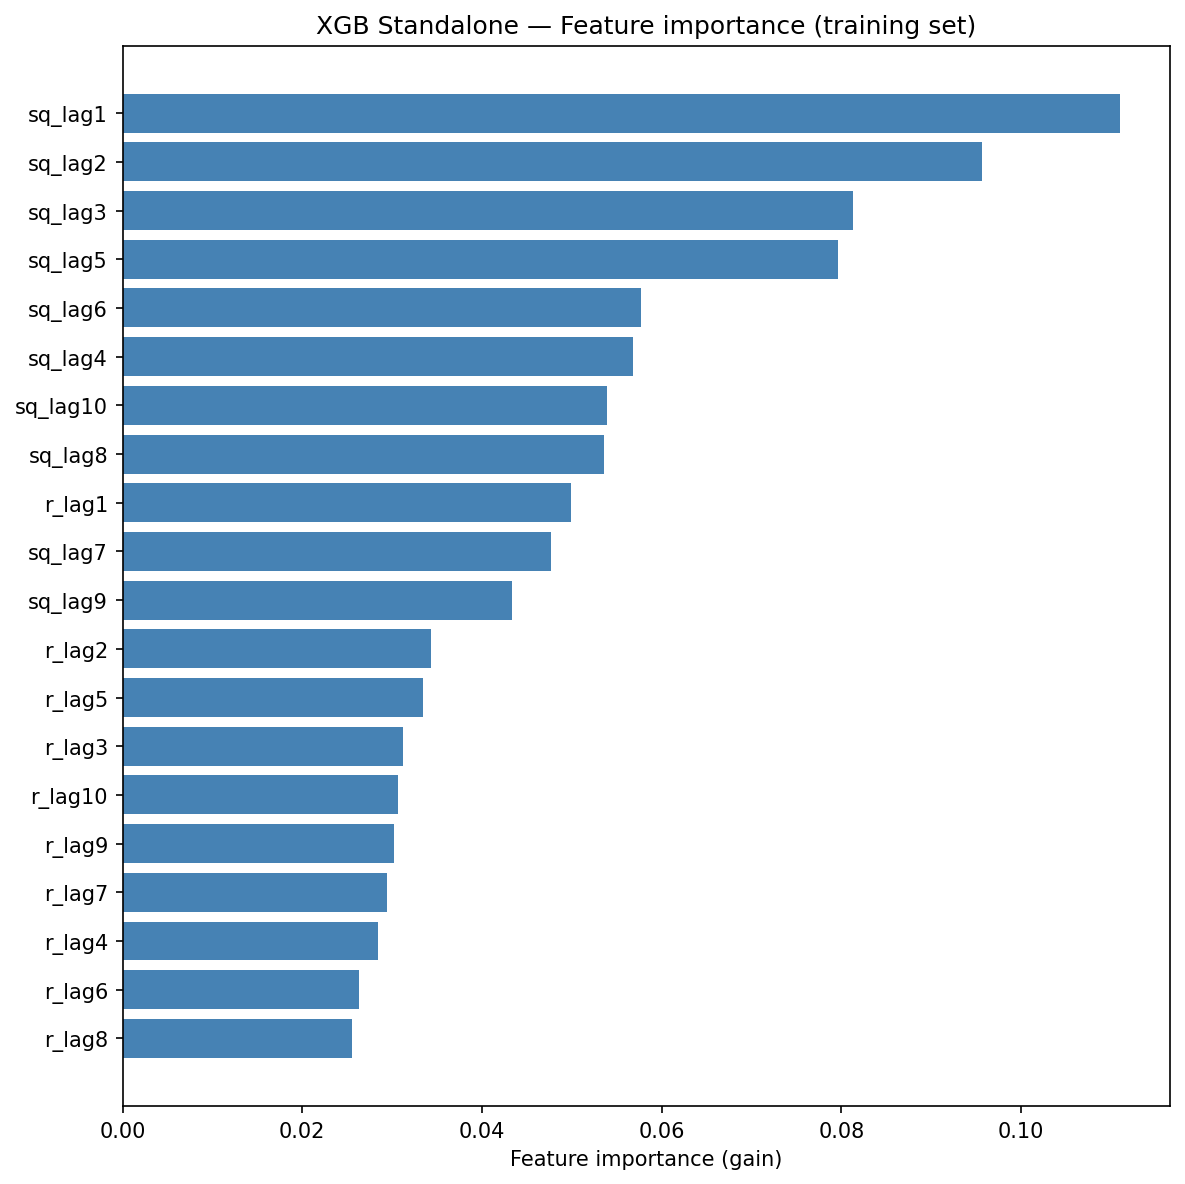

In [26]:
# Fit once on training data for inspection (separate from the rolling evaluation).
# Uses the same target the evaluation scores against, so the importances describe
# the model actually being evaluated rather than one fitted on squared returns.
xgb_viz = XGBVolatilityModel(
    n_lags=XGB_N_LAGS, use_returns=XGB_USE_RETURNS,
    tune="never", xgb_params=XGB_PARAMS,
    target_floor_q=ML_TARGET_FLOOR_Q,
)
xgb_viz.fit(train_returns, target=variance_proxy.reindex(train_returns.index))

feat_names   = xgb_viz.feature_names()
importances  = xgb_viz._model.feature_importances_
order        = np.argsort(importances)

fig, ax = plt.subplots(figsize=(8, max(3, len(feat_names) * 0.4)), dpi=150)
ax.barh([feat_names[i] for i in order], importances[order], color='steelblue')
ax.set_xlabel("Feature importance (gain)")
ax.set_title("XGB Standalone — Feature importance (training set)")
plt.tight_layout()
plt.show()

## 5.3 Forecast vs realized

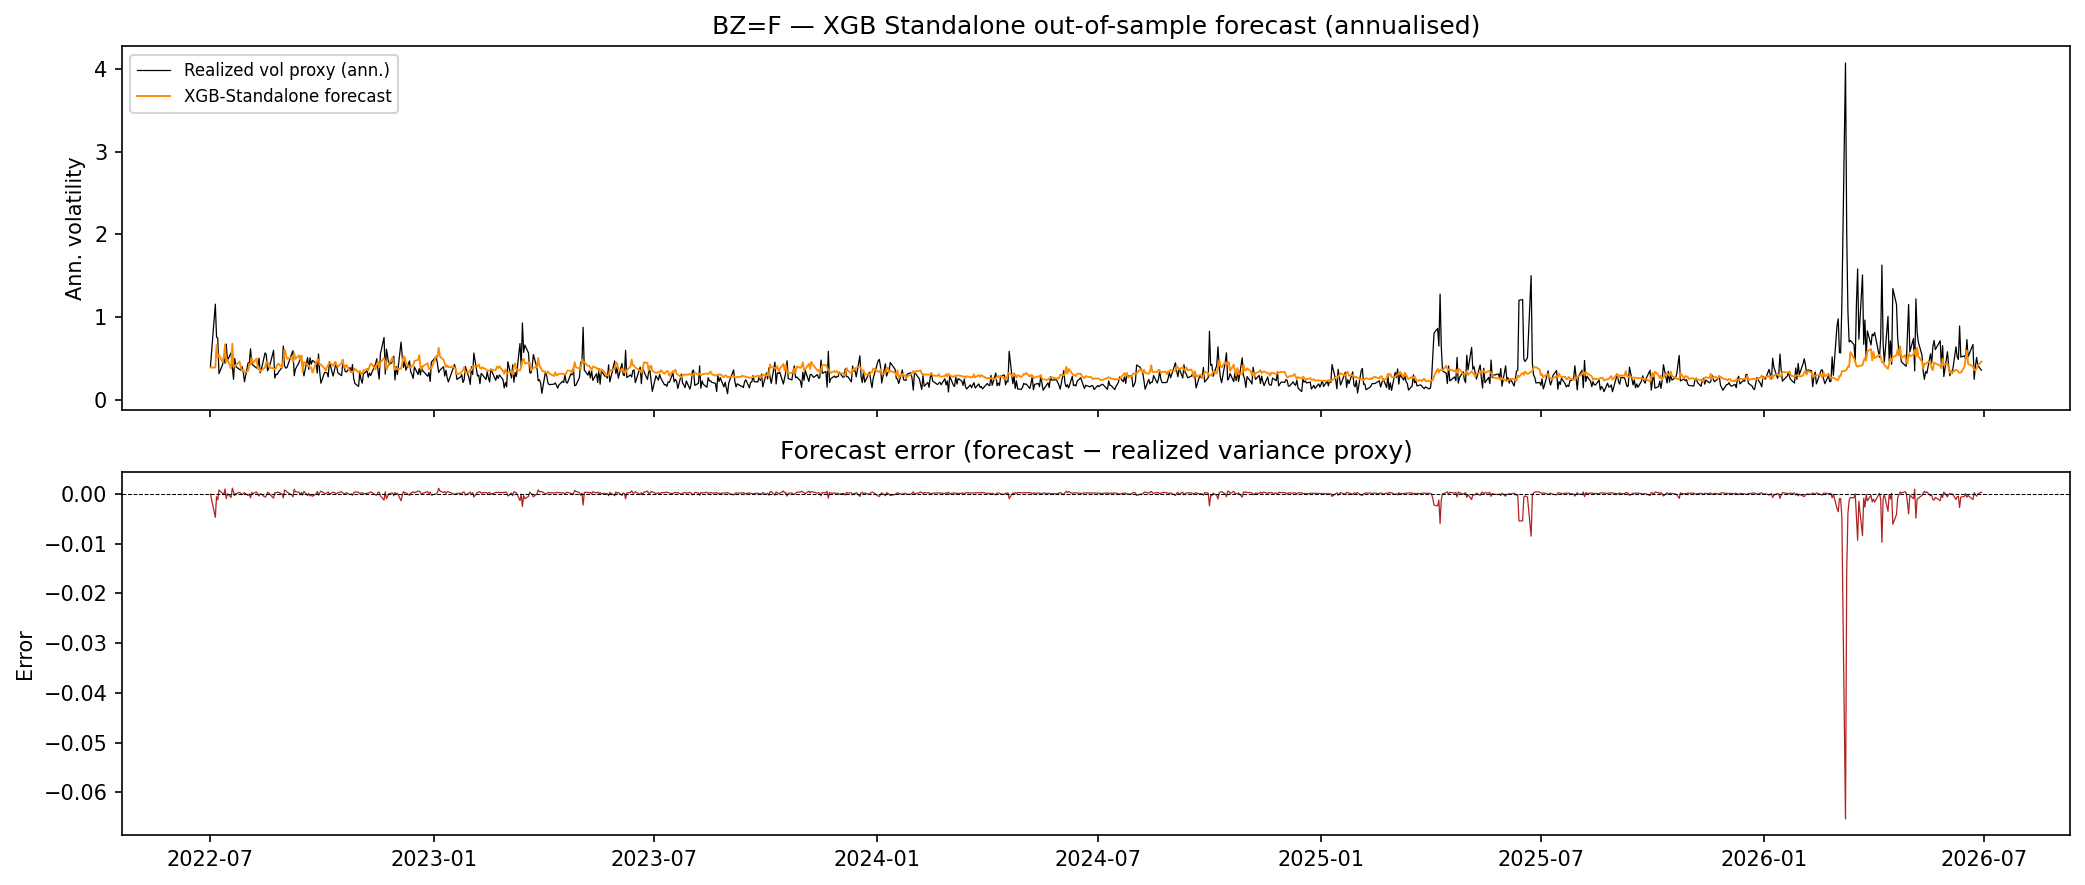

In [27]:
r_xgb = xgb_results["XGB-Standalone"]

fig, axes = plt.subplots(2, 1, figsize=(14, 6), dpi=150, sharex=True)
axes[0].plot(r_xgb.actuals.index.to_timestamp(), np.sqrt(r_xgb.actuals.values * 252),
             color='black', linewidth=0.6, label='Realized vol proxy (ann.)')
axes[0].plot(r_xgb.forecasts.index.to_timestamp(), np.sqrt(r_xgb.forecasts.values * 252),
             color='darkorange', linewidth=0.9, label='XGB-Standalone forecast')
axes[0].set_title(f"{TICKER} — XGB Standalone out-of-sample forecast (annualised)")
axes[0].set_ylabel("Ann. volatility")
axes[0].legend(fontsize=8)
axes[1].plot(r_xgb.errors.index.to_timestamp(), r_xgb.errors.values,
             color='firebrick', linewidth=0.6)
axes[1].axhline(0, color='black', linewidth=0.5, linestyle='--')
axes[1].set_title("Forecast error (forecast − realized variance proxy)")
axes[1].set_ylabel("Error")
plt.tight_layout()
plt.show()

# 6. Hybrid XGBoost

Two hybrid architectures evaluated for each GARCH base model specified in `HYBRID_SPECS`:

| Mode | Description |
|------|-------------|
| `features` | XGB predicts variance directly; GARCH one-step forecast h_{t+1\|t} is included as an additional feature alongside lagged returns. |
| `residual` | **Residual correction**: final forecast = GARCH_forecast + XGB_residual, where XGB is trained to predict the in-sample GARCH residual (r²_t − h_{t\|t-1}). |

## 6.1 Out-of-sample evaluation

In [28]:
_mode_short = {"features": "feat", "residual": "resid"}

hybrid_eval_specs = [
    (
        tuned_factory(XGBHybridModel, tune=HYBRID_TUNE,
                garch_model_type=gt,
                garch_dist=gd,
                mode=m,
                n_lags=HYBRID_N_LAGS,
                use_returns=HYBRID_USE_RETURNS,
                n_trials=HYBRID_N_TRIALS,
                optuna_n_jobs=HYBRID_OPTUNA_JOBS,
                xgb_params=HYBRID_PARAMS,
                target_floor_q=ML_TARGET_FLOOR_Q),
        f"XGB-{gt}-{gd.upper()}-{_mode_short[m]}",
    )
    for gt, gd, m in HYBRID_SPECS
]

hybrid_results: dict[str, ForecastResult] = evaluator.evaluate_many(
    hybrid_eval_specs, train_returns, test_returns,
    actuals_series=variance_proxy,
    train_target_series=ml_train_target,
    verbose=True, n_jobs=PARALLEL_JOBS,
)
print(f"\nCompleted {len(hybrid_results)} hybrid model(s).")

Parallel evaluation: 0 models on 10 worker process(es)...

Completed 0 hybrid model(s).


In [29]:
if hybrid_results:
    hybrid_metrics_df = (
        pd.DataFrame({name: r.metrics() for name, r in hybrid_results.items()})
        .T
        .sort_values("RMSE")
        [["RMSE", "MAE", "MSE", "QLIKE"]]
    )
    display(hybrid_metrics_df)
else:
    print("HYBRID_SPECS is empty - section skipped.")


HYBRID_SPECS is empty - section skipped.


## 6.2 Feature importance (hybrid models)

In [30]:
# Fit one representative hybrid model per mode for inspection.
# Same target as the evaluation (see the standalone section above).
# Uses the first spec for each mode found in HYBRID_SPECS
from collections import OrderedDict

viz_specs = OrderedDict()
for gt, gd, m in HYBRID_SPECS:
    if m not in viz_specs:
        viz_specs[m] = (gt, gd)

for mode, (gt, gd) in viz_specs.items():
    h_viz = XGBHybridModel(
        garch_model_type=gt, garch_dist=gd, mode=mode,
        n_lags=HYBRID_N_LAGS, use_returns=HYBRID_USE_RETURNS,
        tune="never", xgb_params=HYBRID_PARAMS,
        target_floor_q=ML_TARGET_FLOOR_Q,
    )
    h_viz.fit(train_returns, target=variance_proxy.reindex(train_returns.index))

    feat_names  = h_viz.feature_names()
    importances = h_viz._xgb.feature_importances_
    order       = np.argsort(importances)

    fig, ax = plt.subplots(figsize=(8, max(3, len(feat_names) * 0.4)), dpi=150)
    ax.barh([feat_names[i] for i in order], importances[order], color='teal')
    ax.set_xlabel("Feature importance (gain)")
    ax.set_title(f"XGB-Hybrid ({gt}-{gd.upper()}, mode='{mode}') — Feature importance")
    plt.tight_layout()
    plt.show()

## 6.3 Residual decomposition (residual-correction models)

In [31]:
# For each residual-mode hybrid in the results, plot the decomposition:
#   realized variance, GARCH standalone forecast, and final hybrid forecast

resid_names = [name for name in hybrid_results if name.endswith("-resid")]

# Identify corresponding GARCH standalone result for each residual hybrid
for h_name in resid_names:
    # derive base GARCH name from hybrid name, e.g. XGB-GARCH-NORMAL-resid → GARCH-NORMAL
    parts      = h_name.split("-")  # ['XGB', 'GARCH', 'NORMAL', 'resid']
    garch_name = "-".join(parts[1:-1])  # 'GARCH-NORMAL'

    r_h  = hybrid_results[h_name]
    r_g  = garch_results.get(garch_name)

    fig, ax = plt.subplots(figsize=(14, 4), dpi=150)
    ax.plot(r_h.actuals.index.to_timestamp(), np.sqrt(r_h.actuals.values * 252),
            color='black', linewidth=0.6, label='Realized vol proxy (ann.)')
    if r_g is not None:
        ax.plot(r_g.forecasts.index.to_timestamp(), np.sqrt(r_g.forecasts.values * 252),
                color='steelblue', linewidth=0.8, linestyle='--', label=f'{garch_name} (base GARCH)', alpha=0.8)
    ax.plot(r_h.forecasts.index.to_timestamp(), np.sqrt(r_h.forecasts.values * 252),
            color='darkorchid', linewidth=0.9, label=f'{h_name} (hybrid final)')
    ax.set_title(f"{TICKER} — Residual correction: {h_name}")
    ax.set_ylabel("Ann. volatility")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 6.4 Combiner of the GARCH family (XGB-COMB)

The article's hybrid. Instead of one GARCH base, XGBoost receives the one-step forecasts of **every** specification in `COMBINER_GARCH_SPECS`, alongside `ML_N_LAGS` lagged returns and squared returns, and becomes a nonlinear combiner of the GARCH family.

- **Training rows** use each specification's in-sample conditional variance $h_{t+1|t}$, with parameters estimated on the training window only; no test-period information enters.
- **Forecasts** use each specification's genuine one-step forecast, which is exactly what the GARCH rows of section 4.2 report.
- Realized GARCH is not an input, so the information set stays returns only. Tuning, target and floor follow the `HYBRID_*` settings; the benchmark is `GARCH-EW` (section 4.2.1).


In [32]:
xgb_comb_results: dict[str, ForecastResult] = {}
if "xgb" in COMBINER_MODELS:
    xgb_comb_results = evaluator.evaluate_many(
        [(
            tuned_factory(XGBHybridModel, tune=HYBRID_TUNE,
                garch_specs=COMBINER_GARCH_SPECS,
                asym_order=ASYM_ORDER,
                mode="features",
                n_lags=HYBRID_N_LAGS,
                use_returns=HYBRID_USE_RETURNS,
                n_trials=HYBRID_N_TRIALS,
                optuna_n_jobs=HYBRID_OPTUNA_JOBS,
                xgb_params=HYBRID_PARAMS,
                target_floor_q=ML_TARGET_FLOOR_Q),
            "XGB-COMB",
        )],
        train_returns, test_returns,
        actuals_series=variance_proxy,
        train_target_series=ml_train_target,
        verbose=True, n_jobs=1,   # single model; its GARCH fits run inside it
    )
    _m = xgb_comb_results["XGB-COMB"].metrics()
    print(f"\nXGB-COMB over {len(COMBINER_GARCH_SPECS)} GARCH specifications: "
          f"QLIKE = {_m['QLIKE']:.6f}   RMSE = {_m['RMSE']:.6e}")
    if ew_results:
        _ew = ew_results["GARCH-EW"].metrics()
        print(f"GARCH-EW benchmark:                       QLIKE = {_ew['QLIKE']:.6f}   RMSE = {_ew['RMSE']:.6e}")
else:
    print("COMBINER_MODELS does not include 'xgb' - XGB-COMB skipped.")


Evaluating XGB-COMB...
  [XGB-COMB] re-fitted at step 0/1004 (sliding)
  [XGB-COMB] re-fitted at step 10/1004 (sliding)
  [XGB-COMB] re-fitted at step 20/1004 (sliding)
  [XGB-COMB] re-fitted at step 30/1004 (sliding)
  [XGB-COMB] re-fitted at step 40/1004 (sliding)
  [XGB-COMB] re-fitted at step 50/1004 (sliding)
  [XGB-COMB] re-fitted at step 60/1004 (sliding)
  [XGB-COMB] re-fitted at step 70/1004 (sliding)
  [XGB-COMB] re-fitted at step 80/1004 (sliding)
  [XGB-COMB] re-fitted at step 90/1004 (sliding)
  [XGB-COMB] re-fitted at step 100/1004 (sliding)
  [XGB-COMB] re-fitted at step 110/1004 (sliding)
  [XGB-COMB] re-fitted at step 120/1004 (sliding)
  [XGB-COMB] re-fitted at step 130/1004 (sliding)
  [XGB-COMB] re-fitted at step 140/1004 (sliding)
  [XGB-COMB] re-fitted at step 150/1004 (sliding)
  [XGB-COMB] re-fitted at step 160/1004 (sliding)
  [XGB-COMB] re-fitted at step 170/1004 (sliding)
  [XGB-COMB] re-fitted at step 180/1004 (sliding)
  [XGB-COMB] re-fitted at step 190/100

# 7. Standalone LSTM

LSTM trained on a rolling window of `[return, squared_return]` (winsorized, RobustScaler-scaled).
Target: next-step log(squared_return), RobustScaler-scaled, inverse-transformed and exponentiated
back to variance units at forecast time.

> **Retransformation correction.** Trained on log(r²) under MSE, the network estimates E[log r² | X],
> so a plain `exp()` of its output is the conditional *geometric* mean — not the conditional variance
> E[r² | X] that the GARCH and XGB models forecast and that RMSE/QLIKE score. Uncorrected, the LSTM
> forecast came out ≈0.2× the realized level on this data, which QLIKE punishes severely (−2.7 vs
> −6.2) and which pushed every LSTM out of the MCS. `LSTM_RETRANSFORM = "smearing"` applies the
> Duan (1983) smearing factor estimated on the fit residuals; set it to `"none"` to reproduce the
> uncorrected numbers.

## 7.1 Out-of-sample evaluation

In [33]:
lstm_eval_specs = [
    (
        tuned_factory(LSTMVolatilityModel, tune=LSTM_TUNE, n_trials=LSTM_N_TRIALS,
                lookback=LSTM_LOOKBACK,
                hidden_size=LSTM_HIDDEN_SIZE,
                num_layers=LSTM_NUM_LAYERS,
                dropout=LSTM_DROPOUT,
                lr=LSTM_LR,
                max_epochs=LSTM_MAX_EPOCHS,
                patience=LSTM_PATIENCE,
                batch_size=LSTM_BATCH_SIZE,
                val_fraction=LSTM_VAL_FRACTION,
                winsor_limits=LSTM_WINSOR_LIMITS,
                target_floor_q=ML_TARGET_FLOOR_Q,
                retransform=LSTM_RETRANSFORM,
                seed=RANDOM_SEED,
                device=LSTM_DEVICE),
        "LSTM-Standalone",
    )
]

lstm_results: dict[str, ForecastResult] = evaluator.evaluate_many(
    lstm_eval_specs, train_returns, test_returns,
    actuals_series=variance_proxy,
    train_target_series=ml_train_target,
    verbose=True, n_jobs=LSTM_PARALLEL_JOBS,
)
print(f"\nCompleted {len(lstm_results)} standalone LSTM model(s).")


Parallel evaluation: 1 models on 10 worker process(es)...
  [LSTM-Standalone] done  RMSE=2.2946e-03

Completed 1 standalone LSTM model(s).


In [34]:
lstm_metrics_df = (
    pd.DataFrame({name: r.metrics() for name, r in lstm_results.items()})
    .T
    .sort_values("RMSE")
    [["RMSE", "MAE", "MSE", "QLIKE"]]
)
lstm_metrics_df


,RMSE,MAE,MSE,QLIKE
LSTM-Standalone,0.002295,0.000478,0.000005,-6.455262


## 7.2 Forecast vs realized

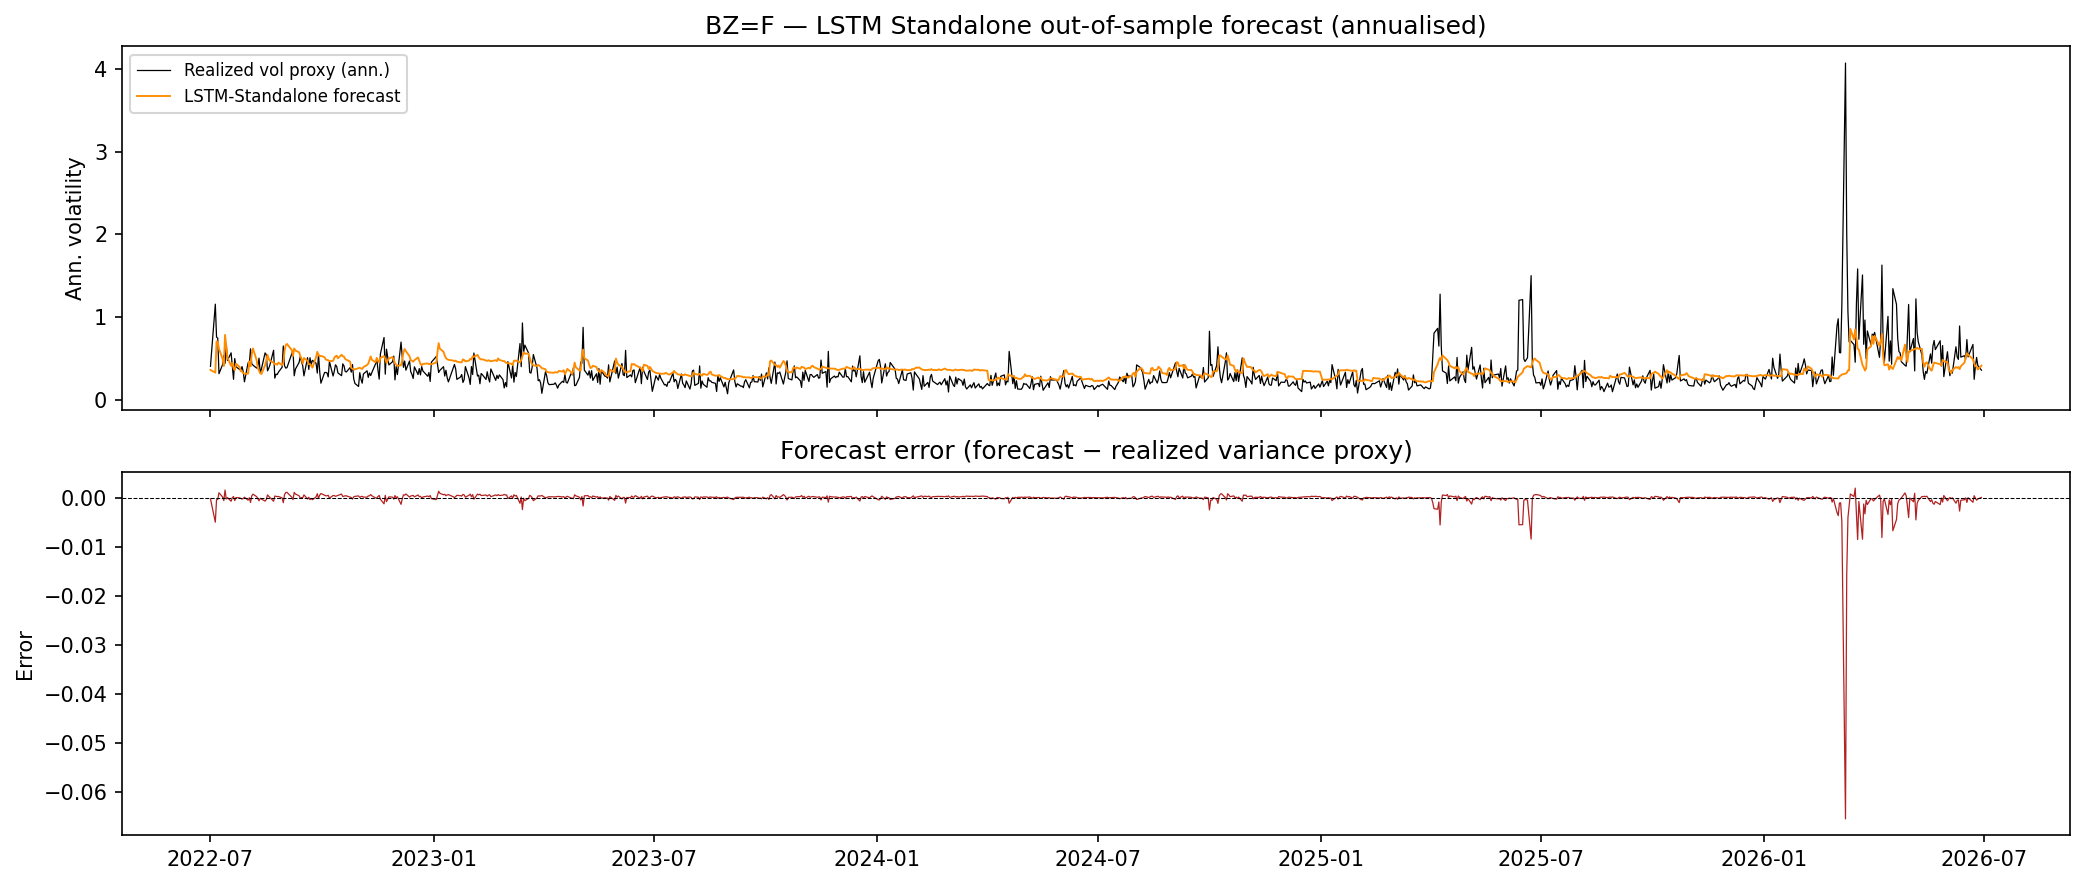

In [35]:
r_lstm = lstm_results["LSTM-Standalone"]

fig, axes = plt.subplots(2, 1, figsize=(14, 6), dpi=150, sharex=True)
axes[0].plot(r_lstm.actuals.index.to_timestamp(), np.sqrt(r_lstm.actuals.values * 252),
              color='black', linewidth=0.6, label='Realized vol proxy (ann.)')
axes[0].plot(r_lstm.forecasts.index.to_timestamp(), np.sqrt(r_lstm.forecasts.values * 252),
              color='darkorange', linewidth=0.9, label='LSTM-Standalone forecast')
axes[0].set_title(f"{TICKER} — LSTM Standalone out-of-sample forecast (annualised)")
axes[0].set_ylabel("Ann. volatility")
axes[0].legend(fontsize=8)
axes[1].plot(r_lstm.errors.index.to_timestamp(), r_lstm.errors.values,
              color='firebrick', linewidth=0.6)
axes[1].axhline(0, color='black', linewidth=0.5, linestyle='--')
axes[1].set_title("Forecast error (forecast − realized variance proxy)")
axes[1].set_ylabel("Error")
plt.tight_layout()
plt.show()


# 8. Hybrid LSTM

Two hybrid architectures evaluated for each GARCH base model specified in `LSTM_HYBRID_SPECS`:

| Mode | Description |
|------|-------------|
| `features` | LSTM inputs are `[return, squared_return]` plus the GARCH one-step forecast h_{t+1\|t} (log-scaled), broadcast across every timestep of the lookback window. |
| `residual` | **Residual correction**: final forecast = GARCH_forecast + LSTM_residual, where LSTM is trained to predict the GARCH residual (r²_t − h_{t\|t-1}). |

`LSTM_RETRANSFORM` applies to `features` mode only — it shares the standalone model's log(r²) target.
`residual` mode is fit on the level scale (r²_t − h_{t|t-1}, which can be negative) and needs no
correction.

## 8.1 Out-of-sample evaluation

In [36]:
_mode_short = {"features": "feat", "residual": "resid"}

lstm_hybrid_eval_specs = [
    (
        tuned_factory(LSTMHybridModel, tune=LSTM_TUNE, n_trials=LSTM_N_TRIALS,
                garch_model_type=gt,
                garch_dist=gd,
                mode=m,
                lookback=LSTM_LOOKBACK,
                hidden_size=LSTM_HIDDEN_SIZE,
                num_layers=LSTM_NUM_LAYERS,
                dropout=LSTM_DROPOUT,
                lr=LSTM_LR,
                max_epochs=LSTM_MAX_EPOCHS,
                patience=LSTM_PATIENCE,
                batch_size=LSTM_BATCH_SIZE,
                val_fraction=LSTM_VAL_FRACTION,
                winsor_limits=LSTM_WINSOR_LIMITS,
                target_floor_q=ML_TARGET_FLOOR_Q,
                retransform=LSTM_RETRANSFORM,
                seed=RANDOM_SEED,
                device=LSTM_DEVICE),
        f"LSTM-{gt}-{gd.upper()}-{_mode_short[m]}",
    )
    for gt, gd, m in LSTM_HYBRID_SPECS
]

lstm_hybrid_results: dict[str, ForecastResult] = evaluator.evaluate_many(
    lstm_hybrid_eval_specs, train_returns, test_returns,
    actuals_series=variance_proxy,
    train_target_series=ml_train_target,
    verbose=True, n_jobs=LSTM_PARALLEL_JOBS,
)
print(f"\nCompleted {len(lstm_hybrid_results)} hybrid LSTM model(s).")


Parallel evaluation: 0 models on 10 worker process(es)...

Completed 0 hybrid LSTM model(s).


In [37]:
if lstm_hybrid_results:
    lstm_hybrid_metrics_df = (
        pd.DataFrame({name: r.metrics() for name, r in lstm_hybrid_results.items()})
        .T
        .sort_values("RMSE")
        [["RMSE", "MAE", "MSE", "QLIKE"]]
    )
    display(lstm_hybrid_metrics_df)
else:
    print("LSTM_HYBRID_SPECS is empty - section skipped.")


LSTM_HYBRID_SPECS is empty - section skipped.


## 8.2 Residual decomposition (residual-correction models)

In [38]:
# For each residual-mode hybrid in the results, plot the decomposition:
#   realized variance, GARCH standalone forecast, and final hybrid forecast

resid_names = [name for name in lstm_hybrid_results if name.endswith("-resid")]

for h_name in resid_names:
    # derive base GARCH name from hybrid name, e.g. LSTM-GARCH-NORMAL-resid → GARCH-NORMAL
    parts      = h_name.split("-")  # ['LSTM', 'GARCH', 'NORMAL', 'resid']
    garch_name = "-".join(parts[1:-1])  # 'GARCH-NORMAL'

    r_h  = lstm_hybrid_results[h_name]
    r_g  = garch_results.get(garch_name)

    fig, ax = plt.subplots(figsize=(14, 4), dpi=150)
    ax.plot(r_h.actuals.index.to_timestamp(), np.sqrt(r_h.actuals.values * 252),
            color='black', linewidth=0.6, label='Realized vol proxy (ann.)')
    if r_g is not None:
        ax.plot(r_g.forecasts.index.to_timestamp(), np.sqrt(r_g.forecasts.values * 252),
                color='steelblue', linewidth=0.8, linestyle='--', label=f'{garch_name} (base GARCH)', alpha=0.8)
    ax.plot(r_h.forecasts.index.to_timestamp(), np.sqrt(r_h.forecasts.values * 252),
            color='darkorchid', linewidth=0.9, label=f'{h_name} (hybrid final)')
    ax.set_title(f"{TICKER} — Residual correction: {h_name}")
    ax.set_ylabel("Ann. volatility")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


## 8.3 Combiner of the GARCH family (LSTM-COMB)

The same combiner with the LSTM. At each of the `LSTM_LOOKBACK` timesteps the network sees the return and the squared return, plus the current one-step forecasts of every specification in `COMBINER_GARCH_SPECS` as constant channels — exactly the information XGB-COMB receives. Training on in-sample conditional variances, forecasting on genuine one-step forecasts, as in 6.4; `LSTM_*` settings.


In [39]:
lstm_comb_results: dict[str, ForecastResult] = {}
if "lstm" in COMBINER_MODELS:
    lstm_comb_results = evaluator.evaluate_many(
        [(
            tuned_factory(LSTMHybridModel, tune=LSTM_TUNE, n_trials=LSTM_N_TRIALS,
                garch_specs=COMBINER_GARCH_SPECS,
                asym_order=ASYM_ORDER,
                mode="features",
                lookback=LSTM_LOOKBACK,
                hidden_size=LSTM_HIDDEN_SIZE,
                num_layers=LSTM_NUM_LAYERS,
                dropout=LSTM_DROPOUT,
                lr=LSTM_LR,
                max_epochs=LSTM_MAX_EPOCHS,
                patience=LSTM_PATIENCE,
                batch_size=LSTM_BATCH_SIZE,
                val_fraction=LSTM_VAL_FRACTION,
                winsor_limits=LSTM_WINSOR_LIMITS,
                target_floor_q=ML_TARGET_FLOOR_Q,
                retransform=LSTM_RETRANSFORM,
                seed=RANDOM_SEED,
                device=LSTM_DEVICE),
            "LSTM-COMB",
        )],
        train_returns, test_returns,
        actuals_series=variance_proxy,
        train_target_series=ml_train_target,
        verbose=True, n_jobs=LSTM_PARALLEL_JOBS,
    )
    _m = lstm_comb_results["LSTM-COMB"].metrics()
    print(f"\nLSTM-COMB over {len(COMBINER_GARCH_SPECS)} GARCH specifications: "
          f"QLIKE = {_m['QLIKE']:.6f}   RMSE = {_m['RMSE']:.6e}")
    if ew_results:
        _ew = ew_results["GARCH-EW"].metrics()
        print(f"GARCH-EW benchmark:                      QLIKE = {_ew['QLIKE']:.6f}   RMSE = {_ew['RMSE']:.6e}")
else:
    print("COMBINER_MODELS does not include 'lstm' - LSTM-COMB skipped.")


Parallel evaluation: 1 models on 10 worker process(es)...
  [LSTM-COMB] done  RMSE=2.3019e-03

LSTM-COMB over 10 GARCH specifications: QLIKE = -6.512607   RMSE = 2.301897e-03
GARCH-EW benchmark:                      QLIKE = -6.662580   RMSE = 2.254300e-03


# 9. Joint Evaluation — All Models

Combined metrics table and forecast overlay across all model groups.

> **Note on QLIKE.** The reported QLIKE is `mean(log h_t + proxy_t / h_t)`, which equals the Patton (2011) robust QLIKE up to a model-independent additive constant. Only *differences* and the *ordering* across models are interpretable — the absolute level (e.g. −6.6) carries no meaning on its own. DM and MCS (which use loss differences) are unaffected by the constant.

> **Note on RMSE across proxies.** RMSE magnitudes are not comparable between different `VARIANCE_PROXY` settings (the target variable differs). Compare RMSE only *within* a single proxy; across proxies, rely on the ranking / QLIKE.

In [40]:
all_results: dict[str, ForecastResult] = {
    **garch_results,
    **realized_results,
    **xgb_results,
    **hybrid_results,
    **lstm_results,
    **lstm_hybrid_results,
    **ew_results,
    **xgb_comb_results,
    **lstm_comb_results,
}

# Guard the merge. A group that was never run (or was lost to a kernel restart)
# would silently vanish from every joint table, the DM matrix and the MCS below,
# and a name reused across two groups would be overwritten without any error.
# Both failure modes look identical from the outside: "my models aren't there".
_sources = {
    "garch_results":       garch_results,
    "xgb_results":         xgb_results,
    "lstm_results":        lstm_results,
}
# Optional groups join the guard only when they were asked for, so an empty
# spec list skips its section instead of tripping the guard (the article runs
# HYBRID_SPECS = [] with the combiners on).
for _asked, _key, _group_results in [
    (bool(HYBRID_SPECS),         "hybrid_results",      hybrid_results),
    (bool(LSTM_HYBRID_SPECS),    "lstm_hybrid_results", lstm_hybrid_results),
    (bool(REALIZED_GARCH_SPECS), "realized_results",    realized_results),
    (GARCH_EW,                   "ew_results",          ew_results),
    ("xgb" in COMBINER_MODELS,   "xgb_comb_results",    xgb_comb_results),
    ("lstm" in COMBINER_MODELS,  "lstm_comb_results",   lstm_comb_results),
]:
    if _asked:
        _sources[_key] = _group_results

_missing = [k for k, v in _sources.items() if not v]
if _missing:
    raise RuntimeError(f"Model group(s) empty: {_missing} — re-run those sections first.")

_n_evaluated = sum(len(v) for v in _sources.values())
if len(all_results) != _n_evaluated:
    _lost = _n_evaluated - len(all_results)
    raise RuntimeError(
        f"all_results holds {len(all_results)} models, but {_n_evaluated} were "
        f"evaluated across {list(_sources)}. "
        + (f"{_lost} name(s) collided and were silently overwritten by the merge."
           if _lost > 0 else
           f"{-_lost} model(s) in all_results come from a group missing from "
           f"_sources — add it there so the guard can see it.")
    )


def _group(name: str) -> str:
    if name == "GARCH-EW":
        return "GARCH equal-weight"
    if name == "XGB-COMB":
        return "XGB Combiner"
    if name == "LSTM-COMB":
        return "LSTM Combiner"
    if name.startswith("XGB-") and "-feat" in name:
        return "XGB Hybrid (features)"
    if name.startswith("XGB-") and "-resid" in name:
        return "XGB Hybrid (residual)"
    if name.startswith("XGB-"):
        return "Standalone XGB"
    if name.startswith("LSTM-") and "-feat" in name:
        return "LSTM Hybrid (features)"
    if name.startswith("LSTM-") and "-resid" in name:
        return "LSTM Hybrid (residual)"
    if name.startswith("LSTM-"):
        return "Standalone LSTM"
    if name.startswith("RealGARCH-"):
        return "Realized GARCH"
    return "GARCH"


all_metrics_df = (
    pd.DataFrame({name: r.metrics() for name, r in all_results.items()})
    .T
    [["RMSE", "MAE", "MSE", "QLIKE"]]
)
all_metrics_df.insert(0, "Group", all_metrics_df.index.map(_group))
all_metrics_df = all_metrics_df.sort_values(["Group", "RMSE"])

print(f"{len(all_metrics_df)} models across {all_metrics_df['Group'].nunique()} groups:")
print(all_metrics_df["Group"].value_counts().to_string(), "\n")

# Best model per group, so no group can be hidden by the global ranking.
print("Best model per group (lowest QLIKE — the loss DM and MCS use):")
print(
    all_metrics_df.sort_values("QLIKE").groupby("Group", sort=False).head(1)
    .to_string(float_format=lambda v: f"{v:.6e}"),
    "\n",
)

# Full table — every model, every group. This cell used to display only
# .head(10) of the global RMSE ranking, which silently dropped whole groups
# (no LSTM model ever ranked top-10 on RMSE, so the "all models" table showed
# none of them).
all_metrics_df.sort_values("QLIKE")

16 models across 7 groups:
Group
GARCH                 10
GARCH equal-weight     1
LSTM Combiner          1
Realized GARCH         1
Standalone LSTM        1
Standalone XGB         1
XGB Combiner           1 

Best model per group (lowest QLIKE — the loss DM and MCS use):
                                               Group         RMSE          MAE          MSE         QLIKE
APARCH-NORMAL                                  GARCH 2.235818e-03 4.319027e-04 4.998884e-06 -6.691890e+00
RealGARCH-garman_klass_overnight      Realized GARCH 2.259750e-03 4.043225e-04 5.106469e-06 -6.678152e+00
GARCH-EW                          GARCH equal-weight 2.254300e-03 4.205920e-04 5.081870e-06 -6.662580e+00
XGB-COMB                                XGB Combiner 2.270686e-03 4.254129e-04 5.156017e-06 -6.595897e+00
LSTM-COMB                              LSTM Combiner 2.301897e-03 4.649713e-04 5.298728e-06 -6.512607e+00
XGB-Standalone                        Standalone XGB 2.298639e-03 4.435893e-04 5.283740e-06

,Group,RMSE,MAE,MSE,QLIKE
APARCH-NORMAL,GARCH,0.002236,0.000432,0.000005,-6.691890
RealGARCH-garman_klass_overnight,Realized GARCH,0.002260,0.000404,0.000005,-6.678152
APARCH-T,GARCH,0.002245,0.000435,0.000005,-6.677467
GARCH-T,GARCH,0.002254,0.000416,0.000005,-6.664218
GARCH-EW,GARCH equal-weight,0.002254,0.000421,0.000005,-6.662580
GARCH-NORMAL,GARCH,0.002257,0.000421,0.000005,-6.659473
FIGARCH-T,GARCH,0.002258,0.000417,0.000005,-6.659338
FIGARCH-NORMAL,GARCH,0.002258,0.000417,0.000005,-6.657297
GJR-GARCH-NORMAL,GARCH,0.002253,0.000424,0.000005,-6.645706
GJR-GARCH-T,GARCH,0.002254,0.000417,0.000005,-6.643661


In [41]:
# Forecast-sanity screen across ALL model groups. Two independent failures are
# flagged:
#   degenerate — forecasts numerically broken (variance collapsing toward 0 blows
#                up QLIKE; exploding upward blows up RMSE). One such model
#                poisons the joint metrics, the DM matrix and the MCS for
#                everyone. Observed with EGARCH on short (~500-obs) windows.
#   biased     — forecasts finite and smooth but at the wrong LEVEL, i.e.
#                mean(forecast)/mean(proxy) off by more than 2x. Every model here
#                forecasts the same E[r^2], so this ratio should sit near 1. This
#                catches transform errors (e.g. exponentiating a log-scale target
#                without a retransformation correction), which the degeneracy
#                screen alone passes as clean while QLIKE and the MCS reject the
#                model outright.
diag_df = forecast_diagnostics(all_results)  # warns per affected model

_bad = diag_df.index[diag_df["degenerate"]].tolist()
if _bad:
    print(f"\u26a0 DEGENERATE models — exclude before trusting DM/MCS: {_bad}\n")
else:
    print("\u2713 No degenerate forecasts — metrics are trustworthy.\n")

_biased = diag_df.index[diag_df["biased"] & ~diag_df["degenerate"]].tolist()
if _biased:
    print(f"\u26a0 MIS-SCALED models (mean forecast off by >2x — check the model, "
          f"not the tests): {_biased}\n")
else:
    print("\u2713 All forecasts on the right scale (mean forecast within 2x of the proxy).\n")

diag_df[["n", "min_forecast", "max_forecast", "n_extreme_low",
         "n_extreme_high", "bias_ratio", "RMSE", "QLIKE",
         "degenerate", "biased"]].style.map(
    lambda v: "background-color: #ffcdd2; font-weight: bold" if v is True else "",
    subset=["degenerate", "biased"],
).format({"min_forecast": "{:.2e}", "max_forecast": "{:.2e}", "bias_ratio": "{:.2f}",
          "RMSE": "{:.3e}", "QLIKE": "{:.3e}"})

✓ No degenerate forecasts — metrics are trustworthy.

✓ All forecasts on the right scale (mean forecast within 2x of the proxy).



,n,min_forecast,max_forecast,n_extreme_low,n_extreme_high,bias_ratio,RMSE,QLIKE,degenerate,biased
LSTM-Standalone,1004,1.76e-04,2.92e-03,0,0,0.91,2.295e-03,-6.455e+00,False,False
XGB-Standalone,1004,1.93e-04,1.82e-03,0,0,0.77,2.299e-03,-6.497e+00,False,False
LSTM-COMB,1004,1.76e-04,1.85e-03,0,0,0.84,2.302e-03,-6.513e+00,False,False
EGARCH-T,1004,1.31e-04,2.86e-03,0,0,0.82,2.275e-03,-6.552e+00,False,False
EGARCH-NORMAL,1004,1.30e-04,2.77e-03,0,0,0.81,2.272e-03,-6.576e+00,False,False
XGB-COMB,1004,1.87e-04,2.96e-03,0,0,0.78,2.271e-03,-6.596e+00,False,False
GJR-GARCH-T,1004,1.50e-04,3.50e-03,0,0,0.81,2.254e-03,-6.644e+00,False,False
GJR-GARCH-NORMAL,1004,1.59e-04,3.60e-03,0,0,0.81,2.253e-03,-6.646e+00,False,False
FIGARCH-NORMAL,1004,1.30e-04,3.84e-03,0,0,0.82,2.258e-03,-6.657e+00,False,False
FIGARCH-T,1004,1.37e-04,3.75e-03,0,0,0.83,2.258e-03,-6.659e+00,False,False


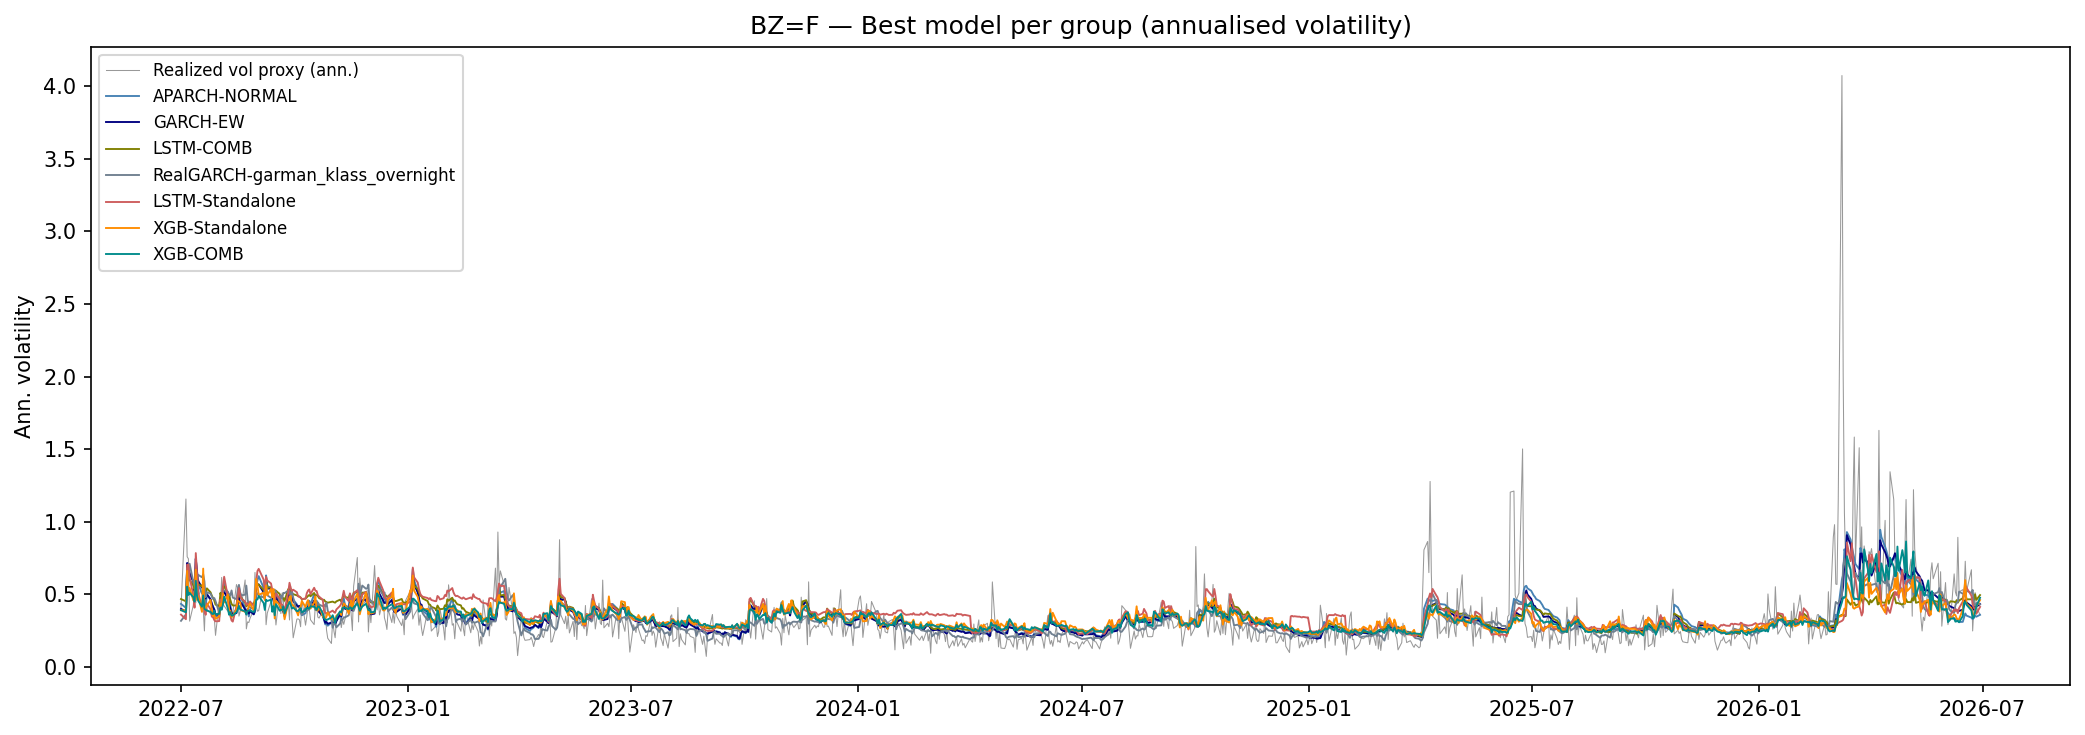

In [42]:
# Best model per group + realized variance overlay
groups = all_metrics_df["Group"].unique()
palette = {
    "GARCH": "steelblue",
    "Standalone XGB": "darkorange",
    "XGB Hybrid (features)": "teal",
    "XGB Hybrid (residual)": "darkorchid",
    "Standalone LSTM": "indianred",
    "LSTM Hybrid (features)": "seagreen",
    "LSTM Hybrid (residual)": "goldenrod",
    "Realized GARCH": "slategray",
    "GARCH equal-weight": "navy",
    "XGB Combiner": "darkcyan",
    "LSTM Combiner": "olive",
}

fig, ax = plt.subplots(figsize=(14, 5), dpi=150)
# realized vol proxy (use any result's actuals — they are identical)
ref = next(iter(all_results.values()))
ax.plot(ref.actuals.index.to_timestamp(), np.sqrt(ref.actuals.values * 252),
        color='black', linewidth=0.5, alpha=0.4, label='Realized vol proxy (ann.)')

for grp in groups:
    best_name = all_metrics_df[all_metrics_df["Group"] == grp].sort_values("RMSE").index[0]
    r = all_results[best_name]
    ax.plot(r.forecasts.index.to_timestamp(), np.sqrt(r.forecasts.values * 252),
            linewidth=0.9, label=f"{best_name}", color=palette.get(grp, 'gray'))

ax.set_title(f"{TICKER} — Best model per group (annualised volatility)")
ax.set_ylabel("Ann. volatility")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


# 10. Statistical Tests

All model groups evaluated jointly. Two tests are reported: Diebold–Mariano against one benchmark, and the Model Confidence Set as the joint test. The full pairwise DM matrix and its within/between-group split follow as supplementary output.

## 10.1 Diebold–Mariano against the benchmark (reported)

Each model against `DM_BENCHMARK` — GARCH(1,1) with Normal errors, the winner of the first version of the paper — with the Harvey, Leybourne & Newbold (1997) small-sample correction; p-values two-sided from *t*(T−1). H₀: equal expected loss. `loss_diff` and `dm_stat` are model minus benchmark, so **negative = the model is better**. Models that nest the benchmark (GARCH-T, GJR-GARCH-NORMAL) make the loss differential near-degenerate under H₀, which tends to oversize the test; read those rows together with the MCS.


In [43]:
# The DM comparison the article reports: every model against one benchmark.
dm_bench = dm_vs_benchmark(all_results, benchmark=DM_BENCHMARK, loss=TEST_LOSS, h=N_AHEAD, alpha=DM_ALPHA)
print(f"DM (HLN) against {DM_BENCHMARK}  |  {TEST_LOSS} loss  |  benchmark mean loss "
      f"= {dm_bench.attrs['benchmark_mean_loss']:.6f}  |  alpha = {DM_ALPHA}")
print(dm_bench["verdict"].value_counts().to_string(), "\n")
dm_bench.sort_values("mean_loss").style.map(
    lambda v: "background-color: #2e7d32; color: #ffffff" if v == "better"
    else ("background-color: #bf360c; color: #ffffff" if v == "worse" else ""),
    subset=["verdict"],
).format({"mean_loss": "{:.6f}", "loss_diff": "{:+.6f}", "dm_stat": "{:+.3f}", "p_value": "{:.4f}"})


DM (HLN) against GARCH-NORMAL  |  qlike loss  |  benchmark mean loss = -6.659473  |  alpha = 0.05
verdict
n.s.     9
worse    6 



,mean_loss,loss_diff,dm_stat,p_value,verdict
model,,,,,
APARCH-NORMAL,-6.691890,-0.032416,-1.581,0.1141,n.s.
RealGARCH-garman_klass_overnight,-6.678152,-0.018679,-1.344,0.1792,n.s.
APARCH-T,-6.677467,-0.017994,-1.558,0.1195,n.s.
GARCH-T,-6.664218,-0.004745,-0.914,0.3608,n.s.
GARCH-EW,-6.662580,-0.003107,-0.794,0.4271,n.s.
FIGARCH-T,-6.659338,+0.000136,+0.011,0.9911,n.s.
FIGARCH-NORMAL,-6.657297,+0.002176,+0.206,0.8366,n.s.
GJR-GARCH-NORMAL,-6.645706,+0.013767,+0.891,0.3729,n.s.
GJR-GARCH-T,-6.643661,+0.015812,+1.154,0.2488,n.s.


### 10.1.1 Full pairwise DM matrix (supplementary)

Every pair of models, for reference. Not reported in the article: the number of pairs grows quadratically and carries no family-wise error control, which is what the MCS provides. Negative MDM statistic → row model has lower loss than column model.


In [44]:
dm_stat_df, dm_pval_df = dm_matrix(all_results, h=N_AHEAD, loss=TEST_LOSS)

print("MDM statistics (upper triangle):")
dm_stat_df.round(3)

MDM statistics (upper triangle):


,GARCH-NORMAL,GARCH-T,GJR-GARCH-NORMAL,GJR-GARCH-T,EGARCH-NORMAL,EGARCH-T,APARCH-NORMAL,APARCH-T,FIGARCH-NORMAL,FIGARCH-T,RealGARCH-garman_klass_overnight,XGB-Standalone,LSTM-Standalone,GARCH-EW,XGB-COMB,LSTM-COMB
GARCH-NORMAL,NaN,0.914,-0.891,-1.154,-2.262,-2.018,1.581,1.558,-0.206,-0.011,1.344,-2.248,-1.974,0.794,-2.847,-2.183
GARCH-T,NaN,NaN,-1.022,-1.611,-2.435,-2.238,1.137,0.938,-0.661,-0.483,0.995,-2.445,-2.108,-0.350,-3.529,-2.396
GJR-GARCH-NORMAL,NaN,NaN,NaN,-0.173,-2.376,-1.789,1.972,1.499,0.599,0.607,1.362,-1.878,-1.722,1.191,-1.756,-1.787
GJR-GARCH-T,NaN,NaN,NaN,NaN,-2.702,-2.142,1.613,1.473,0.847,0.931,1.599,-2.149,-1.898,1.745,-2.576,-2.065
EGARCH-NORMAL,NaN,NaN,NaN,NaN,NaN,-0.819,2.240,2.186,2.214,2.233,2.446,-1.199,-1.247,2.499,0.681,-1.011
EGARCH-T,NaN,NaN,NaN,NaN,NaN,NaN,1.943,1.985,2.040,2.166,2.262,-1.293,-1.377,2.172,1.228,-0.967
APARCH-NORMAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.201,-1.344,-1.136,-0.536,-2.135,-1.943,-1.333,-2.324,-2.086
APARCH-T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.208,-0.981,0.040,-2.245,-2.008,-1.137,-2.582,-2.194
FIGARCH-NORMAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.401,1.507,-2.276,-1.993,0.542,-2.880,-2.206
FIGARCH-T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.332,-2.437,-2.099,0.294,-3.360,-2.376


In [45]:
print(f"DM p-values — highlighted: p < {DM_ALPHA}")
dm_pval_df.round(4).style.map(
    lambda v: "background-color: #c8e6c9; font-weight: bold"
    if (not pd.isna(v) and v < DM_ALPHA) else "",
)

DM p-values — highlighted: p < 0.05


,GARCH-NORMAL,GARCH-T,GJR-GARCH-NORMAL,GJR-GARCH-T,EGARCH-NORMAL,EGARCH-T,APARCH-NORMAL,APARCH-T,FIGARCH-NORMAL,FIGARCH-T,RealGARCH-garman_klass_overnight,XGB-Standalone,LSTM-Standalone,GARCH-EW,XGB-COMB,LSTM-COMB
GARCH-NORMAL,nan,0.360800,0.372900,0.248800,0.023900,0.043900,0.114100,0.119500,0.836600,0.991100,0.179200,0.024800,0.048700,0.427100,0.004500,0.029300
GARCH-T,nan,nan,0.307000,0.107400,0.015100,0.025400,0.255900,0.348400,0.508600,0.629400,0.319800,0.014600,0.035300,0.726400,0.000400,0.016700
GJR-GARCH-NORMAL,nan,nan,nan,0.862600,0.017700,0.074000,0.048800,0.134200,0.549400,0.544200,0.173600,0.060700,0.085300,0.234000,0.079300,0.074200
GJR-GARCH-T,nan,nan,nan,nan,0.007000,0.032400,0.107000,0.141000,0.397200,0.351800,0.110200,0.031900,0.057900,0.081300,0.010100,0.039200
EGARCH-NORMAL,nan,nan,nan,nan,nan,0.413000,0.025300,0.029100,0.027100,0.025800,0.014600,0.231000,0.212800,0.012600,0.496000,0.312300
EGARCH-T,nan,nan,nan,nan,nan,nan,0.052300,0.047400,0.041600,0.030500,0.023900,0.196300,0.168900,0.030100,0.219600,0.334000
APARCH-NORMAL,nan,nan,nan,nan,nan,nan,nan,0.230100,0.179300,0.256400,0.592000,0.033000,0.052300,0.182700,0.020300,0.037200
APARCH-T,nan,nan,nan,nan,nan,nan,nan,nan,0.227300,0.326700,0.968000,0.025000,0.044900,0.255700,0.010000,0.028400
FIGARCH-NORMAL,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.688200,0.132100,0.023100,0.046500,0.587700,0.004100,0.027600
FIGARCH-T,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.183200,0.015000,0.036000,0.768800,0.000800,0.017700


### 10.1.2 DM within-group vs between-group split (supplementary)

With 29 models there are 406 pairwise DM tests. Two effects inflate the raw count of significant pairs, so it should not be read at face value:

1. **Multiplicity.** ~20 pairs would be significant at 5% by chance alone, with no family-wise correction (that is what the MCS provides).
2. **(Near-)nesting.** Within the GARCH group, models differing only in the error distribution (e.g. GARCH-NORMAL vs GARCH-T, where Normal is the limiting case of the Student-t) are nearly nested — the loss-differential variance is near-degenerate under H₀, which inflates the DM statistic and makes the standard test oversized (Clark-McCracken; Giacomini-White 2006). A similar caveat applies to hybrid models sharing the same GARCH core.

The split below uses the model **groups** (GARCH / Standalone XGB / XGB Hybrid features / XGB Hybrid residual / Standalone LSTM / LSTM Hybrid features / LSTM Hybrid residual):

- **Between-group** pairs are the core research comparison — *do the ML and hybrid models forecast differently from the GARCH baseline (and from each other)?* These are properly non-nested and the most meaningful.
- **Within-group** pairs (especially inside the GARCH group) carry the nesting/oversizing caveat and should be interpreted with caution.

In [46]:
# Partition the 406 DM pairs by model GROUP (GARCH / XGB / LSTM / hybrids) via _group.
split = dm_family_split(dm_pval_df, alpha=DM_ALPHA, family_of=_group)

total_sig   = split["within"]["n_significant"] + split["between"]["n_significant"]
total_pairs = split["within"]["n_total"] + split["between"]["n_total"]
print(f"DM significant pairs ({TEST_LOSS} loss, p < {DM_ALPHA}): "
      f"{total_sig} / {total_pairs} total\n")

summary_split = pd.DataFrame({
    "n_significant": [split["within"]["n_significant"], split["between"]["n_significant"]],
    "n_total":       [split["within"]["n_total"],       split["between"]["n_total"]],
    "rejection_rate":[split["within"]["rate"],          split["between"]["rate"]],
}, index=["within-group", "between-group (research comparison)"])
print(summary_split.to_string(formatters={"rejection_rate": "{:.1%}".format}))

# Most-rejected models among between-group pairs — surfaces which models are
# genuinely distinguishable across the GARCH / XGB / LSTM / hybrid boundaries.
from collections import Counter
node = Counter()
for a, b, p in split["between"]["pairs"]:
    if p < DM_ALPHA:
        node[a] += 1
        node[b] += 1
print("\nMost frequently rejected models (between-group pairs):")
for name, cnt in node.most_common(8):
    print(f"  {name:<24} [{_group(name):<18}] in {cnt} significant between-group pairs")

DM significant pairs (qlike loss, p < 0.05): 53 / 120 total

                                     n_significant  n_total rejection_rate
within-group                                    15       45          33.3%
between-group (research comparison)             38       75          50.7%

Most frequently rejected models (between-group pairs):
  XGB-COMB                 [XGB Combiner      ] in 9 significant between-group pairs
  XGB-Standalone           [Standalone XGB    ] in 9 significant between-group pairs
  LSTM-COMB                [LSTM Combiner     ] in 9 significant between-group pairs
  LSTM-Standalone          [Standalone LSTM   ] in 7 significant between-group pairs
  GARCH-EW                 [GARCH equal-weight] in 6 significant between-group pairs
  RealGARCH-garman_klass_overnight [Realized GARCH    ] in 6 significant between-group pairs
  GARCH-T                  [GARCH             ] in 4 significant between-group pairs
  FIGARCH-T                [GARCH             ] in 4 si

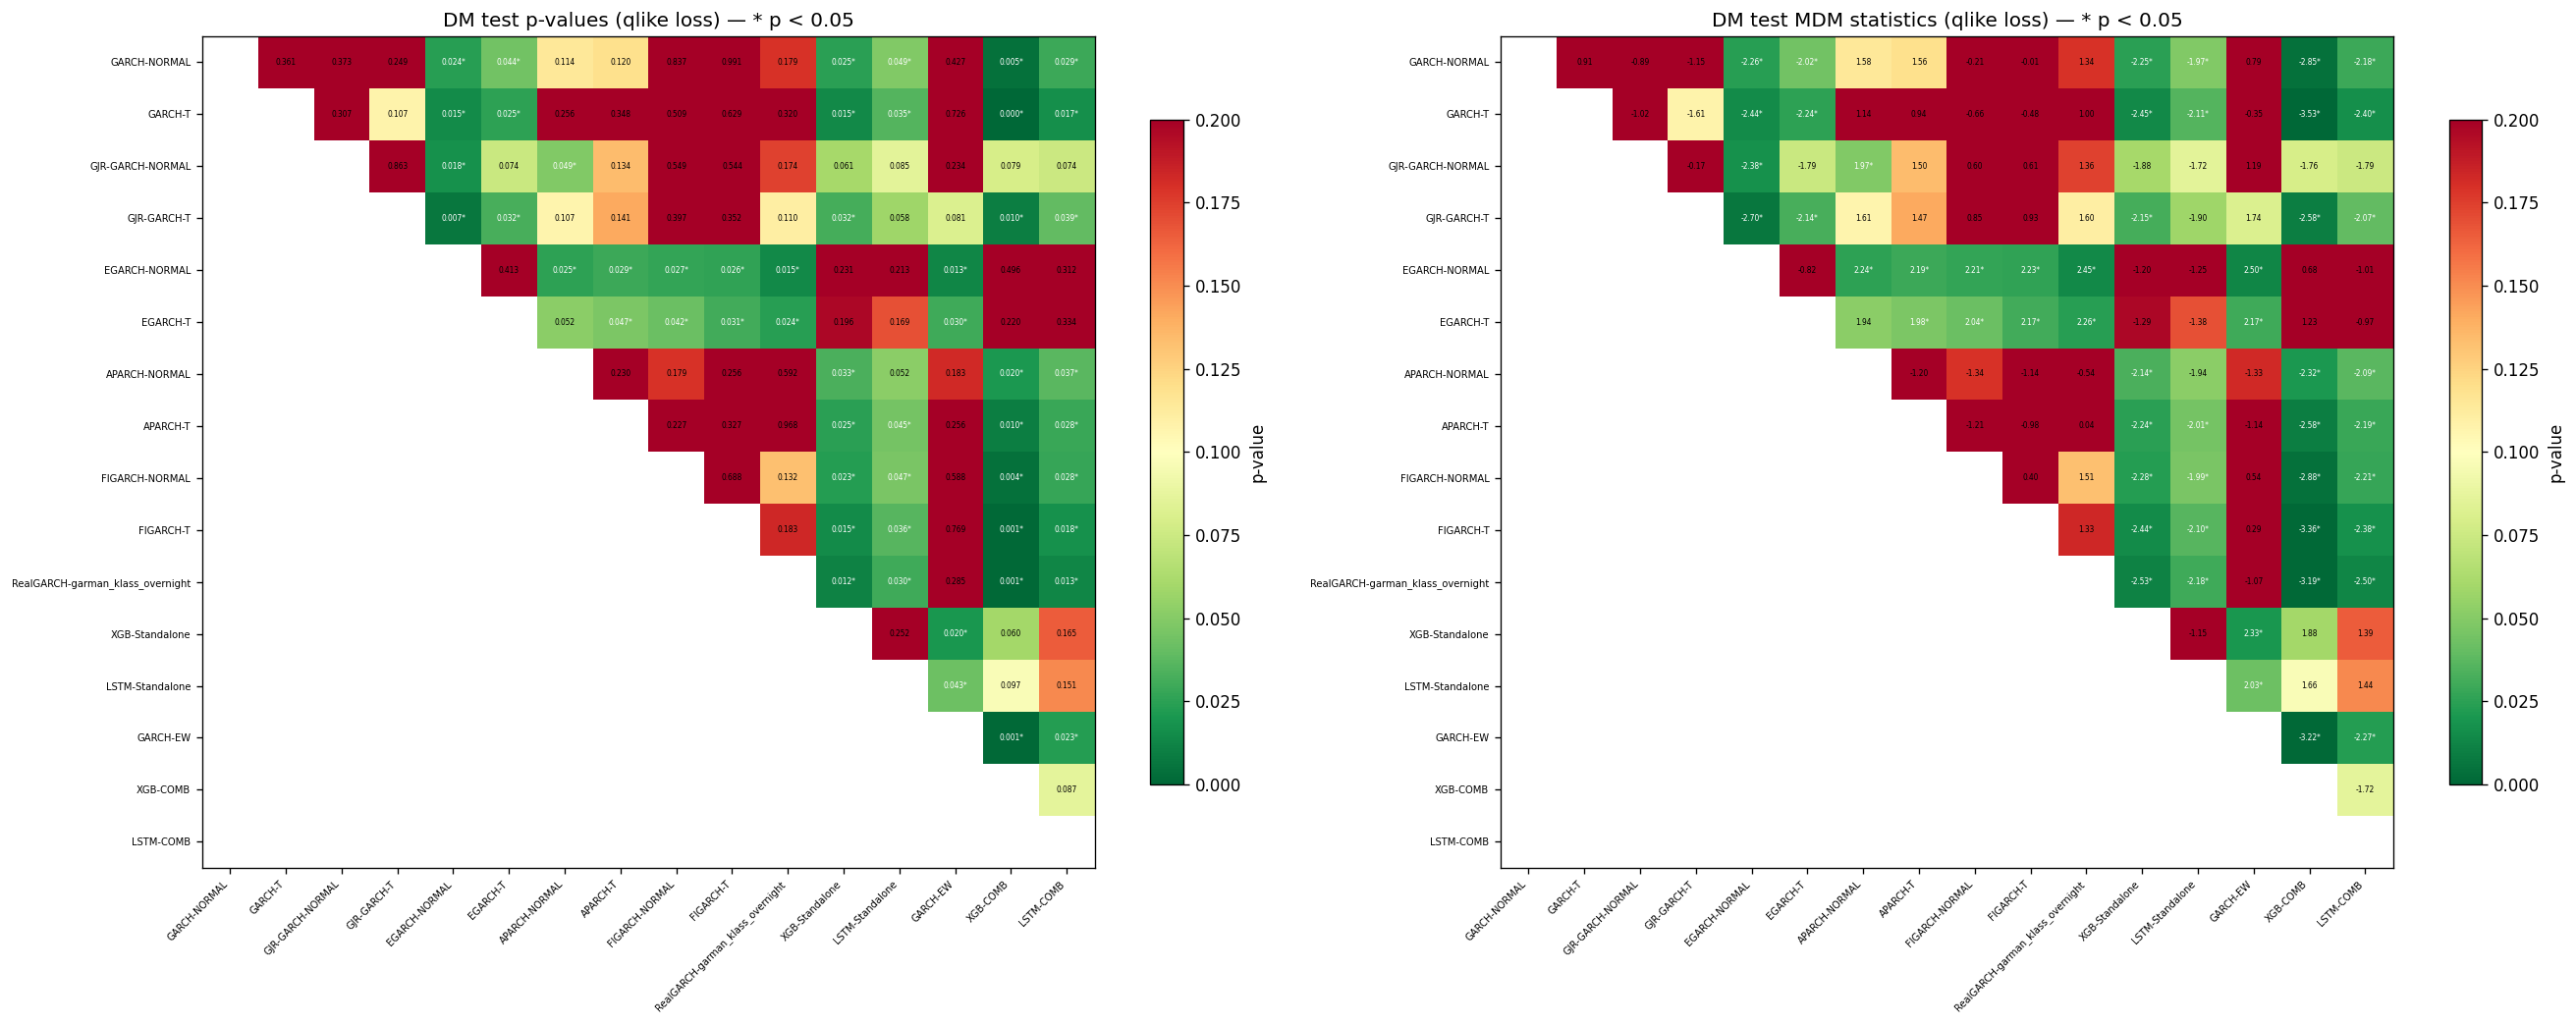

In [47]:
names  = list(all_results.keys())
n_mods = len(names)
pvals  = dm_pval_df.values.astype(float)
stats  = dm_stat_df.values.astype(float)

mask       = np.tril(np.ones_like(pvals, dtype=bool))
pvals_plot = np.where(mask, np.nan, pvals)
stats_plot = np.where(mask, np.nan, stats)

fig, axes = plt.subplots(1, 2, figsize=(max(10, n_mods * 0.7) * 2, max(7, n_mods * 0.55)), dpi=120)

for ax, data, title_suffix, fmt in zip(
    axes,
    [pvals_plot, stats_plot],
    ["p-values", "MDM statistics"],
    ["{:.3f}", "{:.2f}"],
):
    im = ax.imshow(pvals_plot, cmap="RdYlGn_r", vmin=0, vmax=0.20, aspect="auto")
    plt.colorbar(im, ax=ax, label="p-value", shrink=0.8)
    ax.set_xticks(range(n_mods))
    ax.set_xticklabels(names, rotation=45, ha="right", fontsize=6)
    ax.set_yticks(range(n_mods))
    ax.set_yticklabels(names, fontsize=6)
    ax.set_title(f"DM test {title_suffix} ({TEST_LOSS} loss) — * p < {DM_ALPHA}")
    for i in range(n_mods):
        for j in range(i + 1, n_mods):
            val = data[i, j]
            p   = pvals_plot[i, j]
            if not np.isnan(val):
                sig = "*" if (not np.isnan(p) and p < DM_ALPHA) else ""
                ax.text(j, i, fmt.format(val) + sig,
                        ha="center", va="center", fontsize=4.5,
                        color="white" if (not np.isnan(p) and p < 0.05) else "black")

plt.tight_layout()
plt.show()

## 10.2 Model Confidence Set (MCS)

Hansen, Lunde & Nason (2011). Sequential elimination of the worst model until H₀ of equal
predictive accuracy cannot be rejected. Inference via stationary bootstrap (Politis & Romano 1994).

Models with `mcs_pvalue > MCS_ALPHA` belong to the (1 − MCS_ALPHA) MCS.

The **arch** p-values are the ones reported (T_max statistic). Both implementations use the same stationary-bootstrap mean block length (`MCS_BLOCK_SIZE`) and `N_BOOT` replications; the MCS p-values let a reader apply any significance level.


In [48]:
mcs_result = mcs(
    all_results,
    loss=TEST_LOSS,
    alpha=MCS_ALPHA,
    n_boot=N_BOOT,
    block_size=MCS_BLOCK_SIZE,
    seed=RANDOM_SEED,
)
print(mcs_result)
print()

# NOTE: this procedure stops at the first non-rejection (Hansen et al. 2011),
# so surviving models share the placeholder 1.0 — NOT a real bootstrap p-value.
# mark_early_stop=True shows those as "—" (early_stop=True). For graded within-set
# p-values that rank the survivors, see the arch.bootstrap.MCS cell below.
mcs_result.summary(mark_early_stop=True).style.map(
    lambda v: "background-color: #c8e6c9; font-weight: bold" if v is True else "",
    subset=["in_mcs"],
).format({"mcs_pvalue": "{:.4f}"}, na_rep="—")

MCSResult(alpha=0.05, loss='qlike', block_size=31, n_boot=1000, n_included=16, models=['GARCH-NORMAL', 'GARCH-T', 'GJR-GARCH-NORMAL', 'GJR-GARCH-T', 'EGARCH-NORMAL', 'EGARCH-T', 'APARCH-NORMAL', 'APARCH-T', 'FIGARCH-NORMAL', 'FIGARCH-T', 'RealGARCH-garman_klass_overnight', 'XGB-Standalone', 'LSTM-Standalone', 'GARCH-EW', 'XGB-COMB', 'LSTM-COMB'])



,mcs_pvalue,in_mcs,early_stop
GARCH-NORMAL,—,True,True
GARCH-T,—,True,True
GJR-GARCH-NORMAL,—,True,True
GJR-GARCH-T,—,True,True
EGARCH-NORMAL,—,True,True
EGARCH-T,—,True,True
APARCH-NORMAL,—,True,True
APARCH-T,—,True,True
FIGARCH-NORMAL,—,True,True
FIGARCH-T,—,True,True


In [49]:
arch_mcs_result = arch_mcs(
    all_results,
    loss=TEST_LOSS,
    size=MCS_ALPHA,
    n_boot=N_BOOT,
    seed=RANDOM_SEED,
    block_size=MCS_BLOCK_SIZE,
)

print(f"arch.bootstrap.MCS — {TEST_LOSS} loss, alpha={MCS_ALPHA}")
print(f"Models in MCS: {arch_mcs_result['in_mcs'].sum()} / {len(arch_mcs_result)}")
print(f"Stationary bootstrap: mean block length {arch_mcs_result.attrs['block_size']}, "
      f"{arch_mcs_result.attrs['n_boot']} replications (the same in both implementations)")
print()

# Side-by-side comparison. our_pvalue is "—" for early-stop survivors (placeholder,
# not a real bootstrap value); arch_pvalue gives the graded within-set p-values
# that rank how robustly each model belongs to the MCS. Report arch_pvalue.
comparison = (
    mcs_result.summary(mark_early_stop=True)
    .rename(columns={"mcs_pvalue": "our_pvalue", "in_mcs": "our_in_mcs"})
    .drop(columns=["early_stop"])
)
comparison = comparison.join(
    arch_mcs_result.rename(columns={"mcs_pvalue": "arch_pvalue", "in_mcs": "arch_in_mcs"})
)
comparison.style.map(
    lambda v: "background-color: #c8e6c9; font-weight: bold" if v is True else "",
    subset=["our_in_mcs", "arch_in_mcs"],
).format({"our_pvalue": "{:.4f}", "arch_pvalue": "{:.4f}"}, na_rep="—")

arch.bootstrap.MCS — qlike loss, alpha=0.05
Models in MCS: 16 / 16
Stationary bootstrap: mean block length 31, 1000 replications (the same in both implementations)



,our_pvalue,our_in_mcs,arch_pvalue,arch_in_mcs
GARCH-NORMAL,—,True,0.7130,True
GARCH-T,—,True,0.7470,True
GJR-GARCH-NORMAL,—,True,0.7470,True
GJR-GARCH-T,—,True,0.7130,True
EGARCH-NORMAL,—,True,0.4530,True
EGARCH-T,—,True,0.4090,True
APARCH-NORMAL,—,True,1.0000,True
APARCH-T,—,True,0.7470,True
FIGARCH-NORMAL,—,True,0.7470,True
FIGARCH-T,—,True,0.7470,True


/var/folders/_v/nfq7618558l9gfbcj7cdk0hm0000gn/T/ipykernel_7665/916799016.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(mcs_df["Model"], rotation=45, ha='right', fontsize=7)


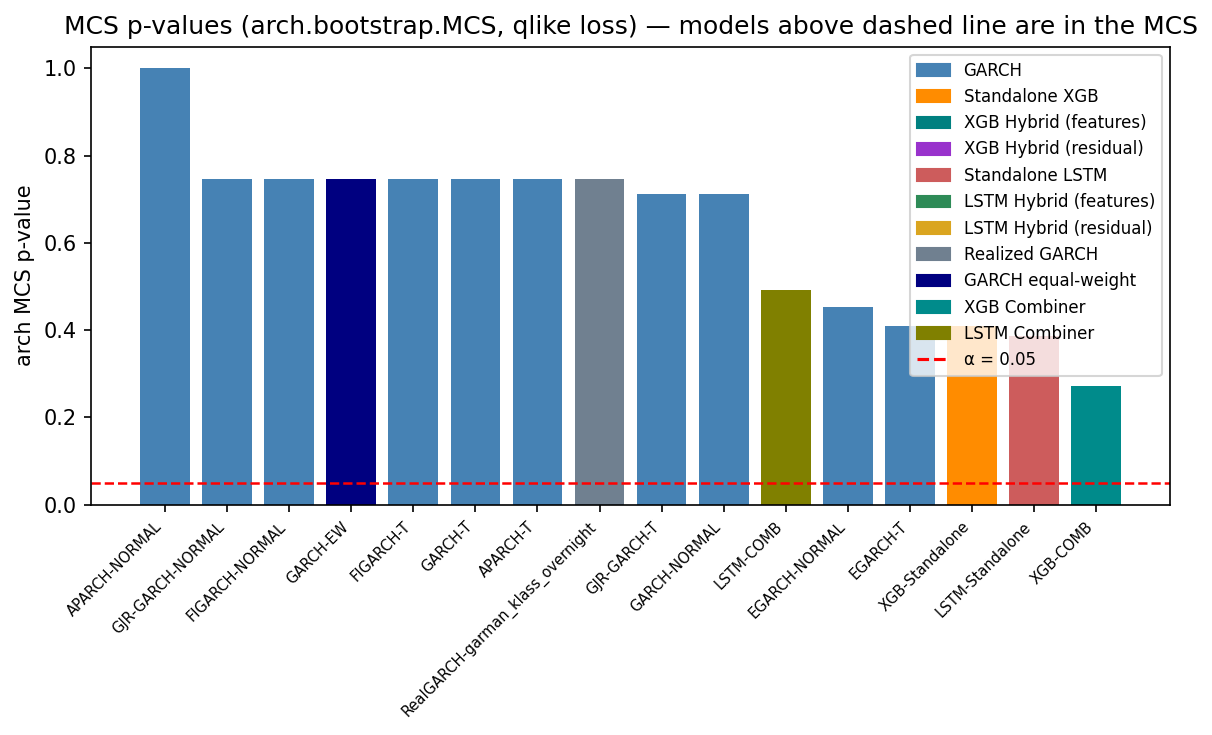

In [50]:
# MCS summary bar chart — arch.bootstrap.MCS p-values per model, coloured by group.
# We plot the arch (graded) p-values rather than our custom-MCS output: the custom
# procedure stops early and assigns a flat placeholder 1.0 to every survivor, which
# would make all in-set bars identical and uninformative. arch gives graded values.
# rename_axis('Model') makes the reset_index column name deterministic regardless of
# how arch names the index.
mcs_df = arch_mcs_result.rename_axis("Model").reset_index()
mcs_df["Group"] = mcs_df["Model"].map(_group)
mcs_df = mcs_df.sort_values("mcs_pvalue", ascending=False)

colors = mcs_df["Group"].map(palette).fillna("gray")

fig, ax = plt.subplots(figsize=(max(8, len(mcs_df) * 0.45), 5), dpi=150)
ax.bar(mcs_df["Model"], mcs_df["mcs_pvalue"], color=colors)
ax.axhline(MCS_ALPHA, color='red', linewidth=1.2, linestyle='--', label=f'α = {MCS_ALPHA}')
ax.set_ylabel("arch MCS p-value")
ax.set_title(f"MCS p-values (arch.bootstrap.MCS, {TEST_LOSS} loss) — models above dashed line are in the MCS")
ax.set_xticklabels(mcs_df["Model"], rotation=45, ha='right', fontsize=7)

# Legend patches
from matplotlib.patches import Patch
legend_elements = [Patch(color=color, label=grp) for grp, color in palette.items()]
legend_elements.append(plt.Line2D([0], [0], color='red', linestyle='--', label=f'α = {MCS_ALPHA}'))
ax.legend(handles=legend_elements, fontsize=8)
plt.tight_layout()
plt.show()

## 10.3 Robustness of the yardstick and of the roll treatment

The same forecasts, re-scored without refitting anything:

- **scored on r²** — against the squared (roll-adjusted) returns, which are unbiased for close-to-close variance by construction but far noisier than the range-based proxy;
- **without roll days** — the main run scored without the calendar contract-roll days. Compare it with a run using `ROLL_HANDLING = "drop"`, which removes those days from the data as well: the difference between the two isolates the effect of the data, the difference between this column and `main` the effect of the days scored.


In [51]:
from scipy.stats import spearmanr

def _score_table(res):
    return pd.DataFrame({n: r.metrics() for n, r in res.items()}).T[["QLIKE", "RMSE"]]

_scored_r2 = rescore(all_results, r2_proxy, proxy="squared returns (roll-adjusted)")
_no_rolls  = exclude_dates(all_results, prepared.roll_days)
_n_dropped = next(iter(_no_rolls.values())).meta.get("dates_dropped", 0)

robust = pd.concat({
    "main": _score_table(all_results),
    "scored on r^2": _score_table(_scored_r2),
    "without roll days": _score_table(_no_rolls),
}, axis=1)
for _col in ["main", "scored on r^2", "without roll days"]:
    robust[(_col, "rank")] = robust[(_col, "QLIKE")].rank().astype(int)
robust = robust.sort_values(("main", "QLIKE"))

_rho = lambda c: spearmanr(robust[("main", "QLIKE")], robust[(c, "QLIKE")])[0]
print(f"Roll days removed from the test-window scoring: {_n_dropped} (ROLL_HANDLING={ROLL_HANDLING!r})")
print(f"Spearman rank correlation of QLIKE with the main ordering: "
      f"scored on r^2 {_rho('scored on r^2'):+.3f}, without roll days {_rho('without roll days'):+.3f}")
robust.style.format({c: ("{:.6f}" if c[1] == "QLIKE" else "{:.3e}" if c[1] == "RMSE" else "{:d}")
                     for c in robust.columns})


Roll days removed from the test-window scoring: 48 (ROLL_HANDLING='adjust')
Spearman rank correlation of QLIKE with the main ordering: scored on r^2 +0.953, without roll days +0.997


## 10.4 Hyperparameters the ML models ran with (supplement)

Read back from the evaluation results: the tuned settings (with `*_TUNE = "first"` one search at the first estimation, reused at every re-estimation; `n_searches` confirms it), the fixed lag window and the training budget.


In [52]:
hp_table = hyperparameter_table(all_results)
hp_table


,tune,n_searches,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_alpha,reg_lambda,...,hidden_size,num_layers,dropout,lr,batch_size,lookback,max_epochs,patience,val_fraction,garch_inputs
model,,,,,,,,,,,,,,,,,,,,,
XGB-Standalone,first,1,80.0,5.0,0.024127,0.545378,0.624492,15.0,0.217193,3.033267,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LSTM-Standalone,first,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,16.0,1.0,0.137120,0.002951,64.0,10.0,100.0,10.0,0.15,NaN
XGB-COMB,first,1,131.0,4.0,0.010017,0.609108,0.724392,4.0,0.032652,0.091350,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0
LSTM-COMB,first,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,16.0,1.0,0.005001,0.000107,128.0,10.0,100.0,10.0,0.15,10.0


# 11. Export of this run

Writes this run's results to `EXPORT_DIR` when `EXPORT_RESULTS = True` (configuration cell): every model's forecasts and per-day losses, the metrics (`REPORT_METRICS`), the tables of the sections above, and `run_config.json` with every setting, the data snapshot's hash, the git commit and the package versions. Tables of sections that did not run are left out. Re-exporting into the same folder replaces only the files the previous export wrote.


In [53]:
if EXPORT_RESULTS:
    _g = globals()
    _results = dict(all_results)
    _tables = {
        "descriptive_stats":         _g.get("stats_df"),
        "returns_dependence":        _g["norm_diag"]["dependence"] if "norm_diag" in _g else None,
        "returns_normality":         _g["norm_diag"]["normality"] if "norm_diag" in _g else None,
        "proxy_diagnostics":         prepared.diagnostics,
        "roll_days":                 pd.DataFrame({"roll_day": prepared.roll_days,
                                                   "in_training_window": prepared.roll_days <= TRAIN_END}),
        "information_criteria":      _g.get("ic_df"),
        "garch_coefficients":        _g.get("coef_matrix"),
        "garch_pvalues":             _g.get("pval_matrix"),
        "asymmetry":                 _g.get("asym_df"),
        "residual_diagnostics":      _g.get("resid_diag"),
        "realized_garch_parameters": _g.get("rg_df"),
        "forecast_diagnostics":      _g.get("diag_df"),
        "dm_vs_benchmark":           _g.get("dm_bench"),
        "dm_pairwise_pvalues":       _g.get("dm_pval_df"),
        "mcs_arch":                  _g.get("arch_mcs_result"),
        "mcs_own":                   _g["mcs_result"].summary(mark_early_stop=True) if "mcs_result" in _g else None,
        "robustness":                _g.get("robust"),
        "hyperparameters":           _g.get("hp_table"),
    }
    _out = export_run(
        EXPORT_DIR, _results,
        tables=_tables,
        config=collect_config(_g),
        extra={"data": data_info,
               "roll_days": [str(d.date()) for d in prepared.roll_days]},
        group_of=_g.get("_group"),
        metrics=REPORT_METRICS,
    )
    print(f"Exported {len(_results)} models and "
          f"{sum(t is not None for t in _tables.values())} tables to\n  {_out}")
    print("  " + ", ".join(sorted(p.name for p in _out.iterdir())))
else:
    print("EXPORT_RESULTS = False - nothing written.")


Exported 16 models and 18 tables to
  /Users/szymonstolarski/Library/CloudStorage/OneDrive-UniwersytetEkonomicznywKatowicach/Doktorat/pipeline may 2026/volatility-pipeline/experiments/17.10.2026/results/BZ=F/2026-10-17_1403_sliding750
  asymmetry.csv, descriptive_stats.csv, dm_pairwise_pvalues.csv, dm_vs_benchmark.csv, forecast_diagnostics.csv, forecasts.csv, garch_coefficients.csv, garch_pvalues.csv, hyperparameters.csv, information_criteria.csv, losses_qlike.csv, losses_squared.csv, mcs_arch.csv, mcs_own.csv, metrics.csv, proxy_diagnostics.csv, realized_garch_parameters.csv, residual_diagnostics.csv, returns_dependence.csv, returns_normality.csv, robustness.csv, roll_days.csv, run_config.json
